# Rotation Source Separation (RSS) Validation

This notebook validates RSS with a physically based acquisition chain. Every generated source angle trajectory is centered to zero temporal mean before it is composed into a virtual-object quaternion, and every active source is required to cross the time axis. Filtered-noise sources start in the stationary distribution of their AR(1) filter and are checked for unintended leading or trailing filter transients. The `piecewise_transient` family intentionally contains smooth transient events as part of its ground-truth signal definition; those events are not initialization artifacts. The resulting initial orientation may be nonidentity. Independent right-handed source and observer triads are rigidly attached to the object and move with it. Consecutive orientations expressed in the observer basis are converted to shortest body-frame rotation increments; their componentwise cumulative sums are the three observer channels, matching integrated gyroscope data. The observer channels remain physically derived and are not independently centered. The recovery matrix is a general direction-cosine rotation in SO(3), parameterized by a three-component rotation vector. The formal experiment uses 200 fresh three-source cases: 50 cases from each standard signal family.

## 1. Imports and package setup

In [1]:
from dataclasses import replace
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

REPO_ROOT = next((candidate for candidate in (Path.cwd(), Path.cwd().parent) if (candidate / 'rss').exists()), None)
if REPO_ROOT is None:
    raise RuntimeError('Could not locate the repository root containing rss/.')
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

from rss import (
    BatchStudyConfig, RSSConfig, SimulationConfig, SuiteCaseSpec,
    build_metrics_frame, build_source_metrics_frame, create_standard_case_specs,
    create_stress_case_specs, export_validation_case_artifacts,
    describe_metric_distributions, generate_family_scenario,
    generate_validation_scenario, run_validation_for_scenario,
    summarize_standard_suite, summarize_stress_suite,
    orthonormality_error,
    source_cross_correlation_matrix,
)
from rss.plotting import (
    plot_loss_history, plot_moving_rotation_geometry, plot_observed_signals, plot_rotation_geometry,
    plot_observer_reconstruction, plot_source_axis_comparison, plot_source_comparison,
)
from bss_baselines import (
    BSSConfig, CorrelationSweepConfig, build_bss_metrics_frame, build_bss_source_metrics_frame,
    build_method_comparison_frames, export_bss_case_artifacts,
    plot_bss_observer_reconstruction, plot_bss_source_comparison,
    plot_method_correlation_curves, plot_method_distribution_grid, plot_method_family_bars,
    plot_method_stress_curves, run_bss_methods_for_scenario,
    run_correlation_sensitivity_sweep,
)
from rss import CorrelationStudyConfig
plt.rcParams['figure.figsize'] = (12, 6)
np.set_printoptions(precision=4, suppress=True)

def display_one_figure(figure):
    """Display exactly one Matplotlib figure, then release it."""
    display(figure)
    plt.close(figure)

SOURCE_ZERO_MEAN_ATOL = 1e-12
FILTERED_NOISE_EDGE_RMS_RATIO_LIMIT = 3.0
SOURCE_SIGNAL_AUDIT = {}

def validate_zero_mean_sources(scenario):
    """Validate zero centering, axis crossing, and stationary-noise edges."""
    source_means = {
        'generated': np.mean(scenario.generated_sources, axis=1),
        'relative': np.mean(scenario.relative_sources, axis=1),
        'recovery': np.mean(scenario.sources, axis=1),
    }
    for label, means in source_means.items():
        if not np.allclose(means, 0.0, rtol=0.0, atol=SOURCE_ZERO_MEAN_ATOL):
            raise RuntimeError(
                f'{scenario.case_id} has nonzero {label} source temporal means: {means.tolist()}'
            )

    active_indices = np.asarray(scenario.active_source_indices, dtype=int)
    active_sources = scenario.sources[active_indices]
    crosses_time_axis = (
        np.min(active_sources, axis=1) < -SOURCE_ZERO_MEAN_ATOL
    ) & (
        np.max(active_sources, axis=1) > SOURCE_ZERO_MEAN_ATOL
    )
    if not np.all(crosses_time_axis):
        failed = active_indices[~crosses_time_axis] + 1
        raise RuntimeError(
            f'{scenario.case_id} sources do not cross the time axis: {failed.tolist()}'
        )

    edge_rms_ratio = np.nan
    if scenario.family == 'filtered_noise':
        sample_count = active_sources.shape[1]
        edge_count = min(max(1, sample_count // 10), (sample_count - 1) // 2)
        interior = active_sources[:, edge_count:-edge_count]
        interior_rms = np.sqrt(np.mean(np.square(interior), axis=1))
        leading_rms = np.sqrt(np.mean(np.square(active_sources[:, :edge_count]), axis=1))
        trailing_rms = np.sqrt(np.mean(np.square(active_sources[:, -edge_count:]), axis=1))
        edge_rms_ratio = float(np.max(
            np.concatenate((leading_rms / interior_rms, trailing_rms / interior_rms))
        ))
        if edge_rms_ratio > FILTERED_NOISE_EDGE_RMS_RATIO_LIMIT:
            raise RuntimeError(
                f'{scenario.case_id} has a filtered-noise edge transient: '
                f'edge/interior RMS ratio={edge_rms_ratio:.3f}'
            )

    SOURCE_SIGNAL_AUDIT[scenario.case_id] = {
        'case_id': scenario.case_id,
        'family': scenario.family,
        'active_source_count': len(active_indices),
        'max_abs_temporal_mean': max(
            float(np.max(np.abs(means))) for means in source_means.values()
        ),
        'all_active_sources_cross_time_axis': bool(np.all(crosses_time_axis)),
        'filtered_noise_max_edge_rms_ratio': edge_rms_ratio,
    }
    return source_means

REPO_ROOT

PosixPath('.')

## 2. Single-case controls and signal generation

For mutual-information loss, select `mi_estimator='gcmi'`, `'bspline'`, `'ksg'`, or `'histogram'`. GCMI and KSG require PSO because ranks and neighbour counts are non-differentiable; B-spline and histogram MI support Adam, SGD, and PSO. All estimates use nats.

In [2]:
QUICK_MODE = False  # Set True for a short smoke run.
single_signal_type = 'harmonic'  # legacy, harmonic, filtered_noise, chirp_modulated, piecewise_transient
single_seed = 0
single_frame_count = 2000
single_dt = 0.01
single_amplitude_tier = 'medium'
source_cross_correlation_limit = 0.01
single_loss_type = 'lagged_cross_correlation'  # lagged_cross_correlation, mutual_information, or action
# single_lags = (0,1,2,3,5,7,11,13,17,19,23,29,31,37,41,43,47)  # Lag 0 is the former zero-lag cross-correlation loss.
single_lags = (0,)  # Lag 0 is the former zero-lag cross-correlation loss.
single_mi_estimator = 'gcmi'  # gcmi, bspline, ksg, or histogram
single_gcmi_rank_method = 'average'
single_bspline_bins = 6
single_bspline_order = 3
single_ksg_k = 4
single_ksg_standardize = True
single_ksg_max_samples = None  # None uses full KSG; set 500, 1000, etc. for a fixed subset.
single_ksg_subsample_mode = 'fixed_random'
single_ksg_subsample_seed = 0
single_mi_bins = 16
single_mi_bandwidth = 0.2
single_action_inertias = (1.0, 1.0, 1.0)
single_action_stiffnesses = (1.0, 1.0, 1.0)
# Optional manual 3 x 3 recovery-matrix initialization.
# In 'so3' mode this must be a proper rotation matrix (A @ A.T = I, det(A) = +1).
# In 'symmetric' mode it must be symmetric. Keep None for identity initialization.
manual_initial_weight_matrix = None
manual_initial_weight_matrix = np.array([
    [-0.4779489885, -0.5421200170, -0.6911372162],
    [-0.5983844737,  0.7769586228, -0.1956305705],
    [ 0.6430402679,  0.3200643460, -0.6957427889],
])

single_rss_config = RSSConfig(
    loss_type=single_loss_type,
    separation_weight=1.0,
    lags=single_lags,
    mi_estimator=single_mi_estimator,
    gcmi_rank_method=single_gcmi_rank_method,
    bspline_bins=single_bspline_bins,
    bspline_order=single_bspline_order,
    ksg_k=single_ksg_k,
    ksg_standardize=single_ksg_standardize,
    ksg_max_samples=single_ksg_max_samples,
    ksg_subsample_mode=single_ksg_subsample_mode,
    ksg_subsample_seed=single_ksg_subsample_seed,
    mi_bins=single_mi_bins,
    mi_bandwidth=single_mi_bandwidth,
    action_inertias=single_action_inertias,
    action_stiffnesses=single_action_stiffnesses,
    epochs=3 if QUICK_MODE else 2000,
    optimizer='pso',  # adam, sgd, or pso
    learning_rate=1e-1,
    learning_rate_end=1e-3,
    sgd_momentum=0.9,
    pso_swarm_size=200, pso_inertia=0.9,
    pso_cognitive=1.0, pso_social=1.5,
    matrix_parameterization='so3',
    # This synthetic body-fixed gyro validation generates integrated body
    # rotation channels, so we explicitly use the integrated_body_rotation path.
    observer_signal_model='integrated_body_rotation',
    initial_weight_matrix=manual_initial_weight_matrix,
    pso_seed=0,
    orthogonality_weight=0.0,
    reconstruction_weight=0.0,
    convergence_tol=0.0,  # RSS always runs the complete epoch budget.
    eps=1e-24,
    quaternion_eps=1e-24,
)
single_sim_config = SimulationConfig(
    seed=single_seed, T=single_frame_count,
    source_cross_correlation_limit=source_cross_correlation_limit,
)
if single_signal_type == 'legacy':
    scenario = generate_validation_scenario(single_sim_config)
else:
    scenario = generate_family_scenario(
        SuiteCaseSpec(
            family=single_signal_type, case_id=f'single_{single_signal_type}',
            seed=single_seed, frame_count=single_frame_count, dt=single_dt,
            amplitude_tier=single_amplitude_tier,
        ),
        single_sim_config, BatchStudyConfig(),
    )
source_means = validate_zero_mean_sources(scenario)
print('Scenario:', scenario.case_id, scenario.observations.shape)
print('Generated source temporal means:', source_means['generated'])
print('Recovery source temporal means:', source_means['recovery'])
original_source_correlation = source_cross_correlation_matrix(scenario.sources)
original_off_diagonal = original_source_correlation[np.triu_indices(3, k=1)]
print('Source cross-correlation limit:', scenario.config.source_cross_correlation_limit)
print('Ground-truth source cross-correlation matrix:')
print(original_source_correlation)
print('Ground-truth pairwise absolute cross-correlations:', np.abs(original_off_diagonal))
print('Ground-truth mean absolute cross-correlation:', np.mean(np.abs(original_off_diagonal)))
print('Ground-truth maximum absolute cross-correlation:', np.max(np.abs(original_off_diagonal)))
print('Ground-truth threshold passed:', np.max(np.abs(original_off_diagonal)) < scenario.config.source_cross_correlation_limit)
print('Physical observation model:', scenario.observation_model)
print('True SO(3) direction-cosine/recovery matrix:')
print(scenario.mixing_matrix)
print('True direction-cosine Gram matrix A A^T:')
print(scenario.mixing_matrix @ scenario.mixing_matrix.T)
print('True matrix orthogonality error:', np.linalg.norm(scenario.mixing_matrix @ scenario.mixing_matrix.T - np.eye(3), ord='fro'))
print('True matrix determinant:', np.linalg.det(scenario.mixing_matrix))
print('Source-axis Gram matrix:')
print(scenario.source_axes_global @ scenario.source_axes_global.T)
print('Observer-axis Gram matrix:')
print(scenario.observer_axes_global @ scenario.observer_axes_global.T)

print('Source-axis orthonormality error:', orthonormality_error(scenario.source_axes_global))
print('Observer-axis orthonormality error:', orthonormality_error(scenario.observer_axes_global))

Scenario: single_harmonic (3, 2000)
Generated source temporal means: [0. 0. 0.]
Recovery source temporal means: [0. 0. 0.]
Source cross-correlation limit: 0.01
Ground-truth source cross-correlation matrix:
[[ 1.  0. -0.]
 [ 0.  1.  0.]
 [-0.  0.  1.]]
Ground-truth pairwise absolute cross-correlations: [0. 0. 0.]
Ground-truth mean absolute cross-correlation: 8.181349463292358e-16
Ground-truth maximum absolute cross-correlation: 1.79313316674314e-15
Ground-truth threshold passed: True
Physical observation model: body_fixed_gyro
True SO(3) direction-cosine/recovery matrix:
[[ 0.4883  0.7814  0.3886]
 [-0.4221  0.6012 -0.6785]
 [-0.7638  0.1672  0.6234]]
True direction-cosine Gram matrix A A^T:
[[ 1. -0. -0.]
 [-0.  1. -0.]
 [-0. -0.  1.]]
True matrix orthogonality error: 8.247839887484569e-16
True matrix determinant: 0.9999999999999996
Source-axis Gram matrix:
[[ 1. -0. -0.]
 [-0.  1.  0.]
 [-0.  0.  1.]]
Observer-axis Gram matrix:
[[ 1.  0.  0.]
 [ 0.  1. -0.]
 [ 0. -0.  1.]]
Source-axis

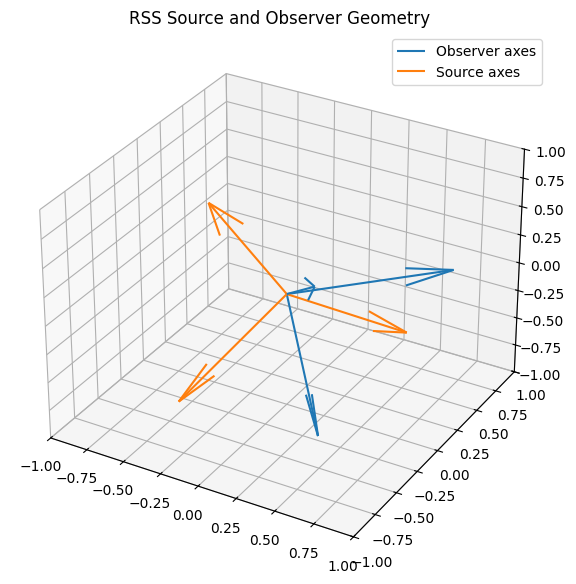

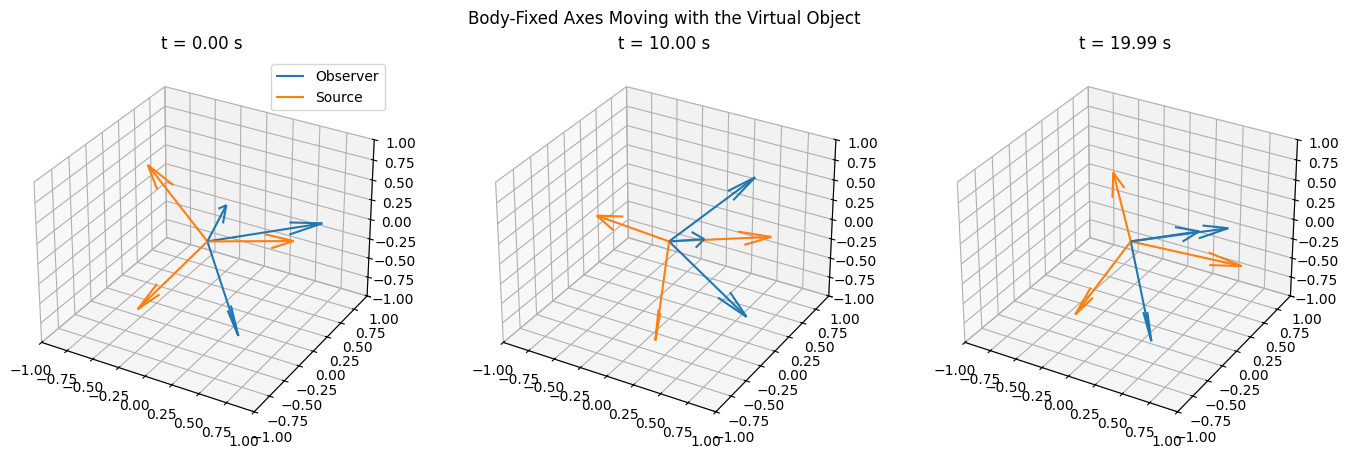

In [3]:
display_one_figure(plot_rotation_geometry(scenario))
display_one_figure(plot_moving_rotation_geometry(scenario))

## 3. Fit RSS and inspect the optimized SO(3) matrix

Optimizer: pso
Primary separation loss: lagged_cross_correlation
MI estimator: gcmi
MI unit: nats
GCMI rank method: average
B-spline bins/order: 6 3
KSG k: 4
KSG standardization: True
KSG maximum samples: None
KSG subsampling mode/seed: fixed_random 0
KSG effective sample count: 2000
Applied sample interval (s): 0.009999999999999787
Initial recovery/weight matrix:
[[-0.4779 -0.5421 -0.6911]
 [-0.5984  0.777  -0.1956]
 [ 0.643   0.3201 -0.6957]]
Learning-rate schedule: exponential
Configured learning-rate start: 0.1
Configured learning-rate end: 0.001
First applied learning rate: 0.1
Terminal applied learning rate: 0.001
Optimized six weights: [ 1.1033  0.2108 -2.1545]
Optimized SO(3) recovery matrix:
[[-0.3948  0.6485 -0.6508]
 [-0.5101 -0.7439 -0.4318]
 [-0.7642  0.1615  0.6245]]
Recovered direction-cosine Gram matrix A A^T:
[[ 1.  0.  0.]
 [ 0.  1. -0.]
 [ 0. -0.  1.]]
Symmetry error: 1.8477442906469717
Orthogonality error: 5.530999354716012e-16
Determinant: 1.0000000000000002
Singul

q_R observed                               q_S source-composed            \
             w         x         y         z                   w         x   
0     0.988341 -0.148553  0.012565 -0.030922            0.988341 -0.148553   
1     0.984356 -0.169980 -0.001524 -0.046344            0.984356 -0.169980   
2     0.979463 -0.191450 -0.014871 -0.061462            0.979463 -0.191450   
3     0.973865 -0.212260 -0.026933 -0.076200            0.973865 -0.212260   
4     0.967845 -0.231727 -0.037191 -0.090532            0.967845 -0.231727   
5     0.961737 -0.249211 -0.045179 -0.104473            0.961737 -0.249211   
6     0.955900 -0.264128 -0.050504 -0.118073            0.955900 -0.264128   
7     0.950675 -0.275968 -0.052878 -0.131389            0.950675 -0.275968   
8     0.946353 -0.284298 -0.052129 -0.144475            0.946353 -0.284298   
9     0.943146 -0.288772 -0.048218 -0.157357            0.943146 -0.288772   

                      q_delta closest to I                              \
          y         z                    w             x             y   
0  0.012565 -0.030922                  1.0  5.610746e-17 -1.474515e-17   
1 -0.001524 -0.046344                  1.0  2.901596e-17 -2.602085e-17   
2 -0.014871 -0.061462                  1.0  8.380883e-17 -1.734723e-18   
3 -0.026933 -0.076200                  1.0  1.734723e-18 -2.081668e-17   
4 -0.037191 -0.090532                  1.0  8.456777e-17  3.469447e-18   
5 -0.045179 -0.104473                  1.0  5.724587e-17  0.000000e+00   
6 -0.050504 -0.118073                  1.0  1.075529e-16  4.163336e-17   
7 -0.052878 -0.131389                  1.0  1.153591e-16 -6.938894e-18   
8 -0.052129 -0.144475                  1.0  3.469447e-18 -2.081668e-17   
9 -0.048218 -0.157357                  1.0  1.561251e-16  9.020562e-17   

                 
              z  
0 -6.938894e-18  
1 -6.938894e-18  
2  1.387779e-17  
3  1.387779e-17  
4  4.163336e-17  
5  4.163336e-17  
6  2.775558e-17  
7  1.110223e-16  
8  0.000000e+00  
9  5.551115e-17

Ground-truth source cross-correlation matrix:
[[ 1.  0. -0.]
 [ 0.  1.  0.]
 [-0.  0.  1.]]
Matched separated-source cross-correlation matrix:
[[ 1.  0. -0.]
 [ 0.  1.  0.]
 [-0.  0.  1.]]
Ground-truth maximum absolute cross-correlation: 1.79313316674314e-15
Separated maximum absolute cross-correlation: 1.4554614601294845e-16
Ground-truth threshold passed: True


,value
rss_optimizer,pso
rss_loss_type,lagged_cross_correlation
rss_mi_estimator,gcmi
rss_mi_unit,nats
rss_gcmi_rank_method,average
...,...
rss_best_normalized_reconstruction_loss,0.0
rss_best_epoch,634.0
matrix_condition_number,1.0
matrix_orthogonality_error,0.0


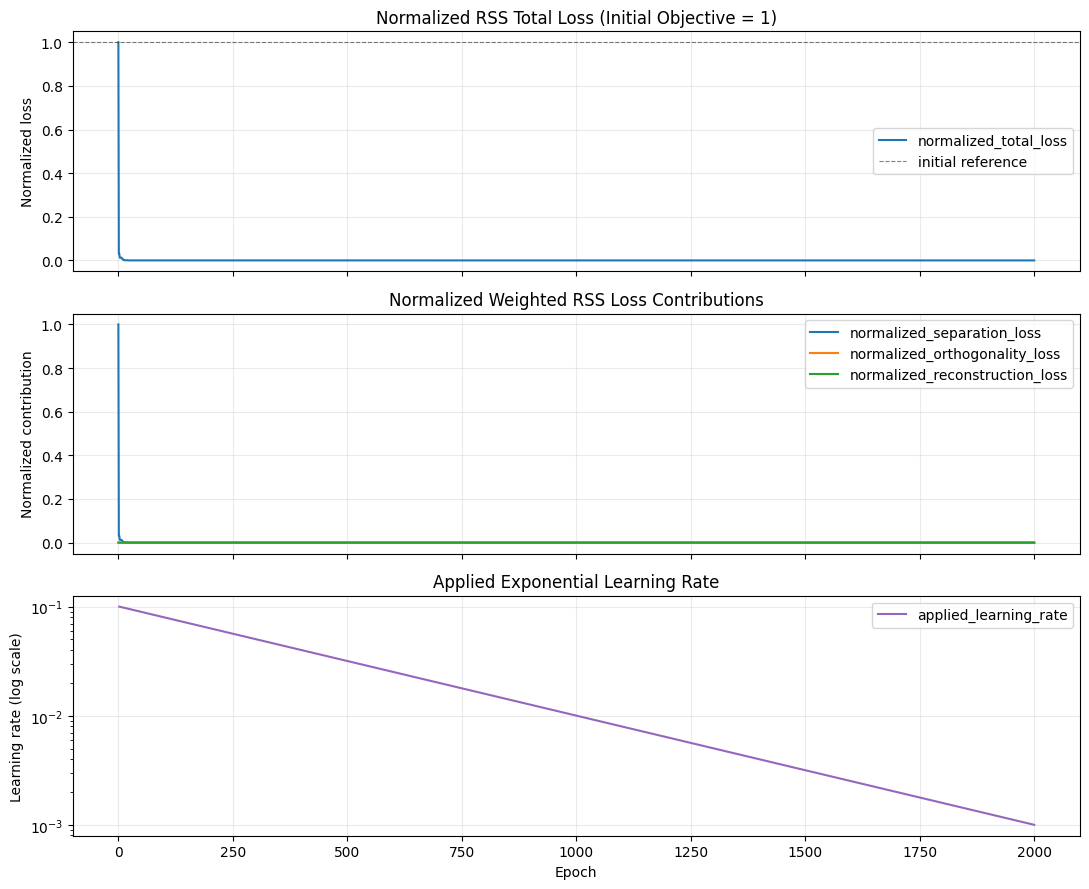

In [4]:
validation = run_validation_for_scenario(scenario, single_rss_config)
rss_result = validation.rss_result
print('Optimizer:', rss_result.optimizer_name)
print('Primary separation loss:', rss_result.config.loss_type)
print('MI estimator:', rss_result.config.mi_estimator)
print('MI unit: nats')
print('GCMI rank method:', rss_result.config.gcmi_rank_method)
print('B-spline bins/order:', rss_result.config.bspline_bins, rss_result.config.bspline_order)
print('KSG k:', rss_result.config.ksg_k)
print('KSG standardization:', rss_result.config.ksg_standardize)
print('KSG maximum samples:', rss_result.config.ksg_max_samples)
print('KSG subsampling mode/seed:', rss_result.config.ksg_subsample_mode, rss_result.config.ksg_subsample_seed)
effective_ksg_samples = rss_result.source_angles.shape[1] if rss_result.config.ksg_max_samples is None else min(rss_result.source_angles.shape[1], rss_result.config.ksg_max_samples)
print('KSG effective sample count:', effective_ksg_samples)
print('Applied sample interval (s):', rss_result.sample_interval_seconds)
print('Initial recovery/weight matrix:')
print(rss_result.config.resolved_initial_matrix)
print('Learning-rate schedule: exponential')
print('Configured learning-rate start:', rss_result.config.learning_rate)
print('Configured learning-rate end:', rss_result.config.learning_rate_end)
print('First applied learning rate:', rss_result.applied_learning_rates[0] if rss_result.applied_learning_rates else None)
print('Terminal applied learning rate:', rss_result.applied_learning_rates[-1] if rss_result.applied_learning_rates else None)
print('Optimized six weights:', rss_result.optimized_weights)
print('Optimized SO(3) recovery matrix:')
print(rss_result.recovery_matrix)
print('Recovered direction-cosine Gram matrix A A^T:')
print(rss_result.recovery_matrix @ rss_result.recovery_matrix.T)
print('Symmetry error:', rss_result.matrix_diagnostics.symmetry_error)
print('Orthogonality error:', rss_result.matrix_diagnostics.orthogonality_error)
print('Determinant:', rss_result.matrix_diagnostics.determinant)
print('Singular values:', rss_result.matrix_diagnostics.singular_values)
print('Condition number:', rss_result.matrix_diagnostics.condition_number)
print('Warnings:', rss_result.matrix_diagnostics.warnings)
print('Stop reason:', rss_result.stop_reason, '| best epoch:', rss_result.best_epoch)
print('Raw initial-loss normalization reference:', rss_result.loss_normalization_reference)
print('Normalized initial loss:', rss_result.normalized_initial_loss)
print('Normalized best loss:', rss_result.normalized_best_loss)
print('Normalized terminal loss:', rss_result.normalized_terminal_loss)
best_history = rss_result.loss_history[rss_result.best_epoch]
print('Raw full-quaternion reconstruction loss:', best_history['reconstruction_loss'])
print('Normalized weighted reconstruction contribution:', best_history['normalized_reconstruction_loss'])
print('Mean relative rotation error (deg):', np.degrees(rss_result.reconstruction_mean_error_rad))
print('Maximum relative rotation error (deg):', np.degrees(rss_result.reconstruction_max_error_rad))
quaternion_comparison = pd.concat(
    {
        'q_R observed': pd.DataFrame(rss_result.observer_quaternions, columns=['w', 'x', 'y', 'z']),
        'q_S source-composed': pd.DataFrame(rss_result.composed_source_quaternions, columns=['w', 'x', 'y', 'z']),
        'q_delta closest to I': pd.DataFrame(rss_result.relative_reconstruction_quaternions, columns=['w', 'x', 'y', 'z']),
    },
    axis=1,
)
display(quaternion_comparison.head(10))
print('Ground-truth source cross-correlation matrix:')
print(validation.original_source_cross_correlation_matrix)
print('Matched separated-source cross-correlation matrix:')
print(validation.separated_source_cross_correlation_matrix)
print('Ground-truth maximum absolute cross-correlation:', validation.metrics['original_source_max_abs_cross_correlation'])
print('Separated maximum absolute cross-correlation:', validation.metrics['separated_source_max_abs_cross_correlation'])
print('Ground-truth threshold passed:', validation.metrics['original_source_max_abs_cross_correlation'] < scenario.config.source_cross_correlation_limit)
display(pd.DataFrame([validation.metrics]).T.rename(columns={0: 'value'}))
display_one_figure(plot_loss_history(rss_result.loss_history))

## 4. Source recovery and geometry evaluation

Observed and true source signals


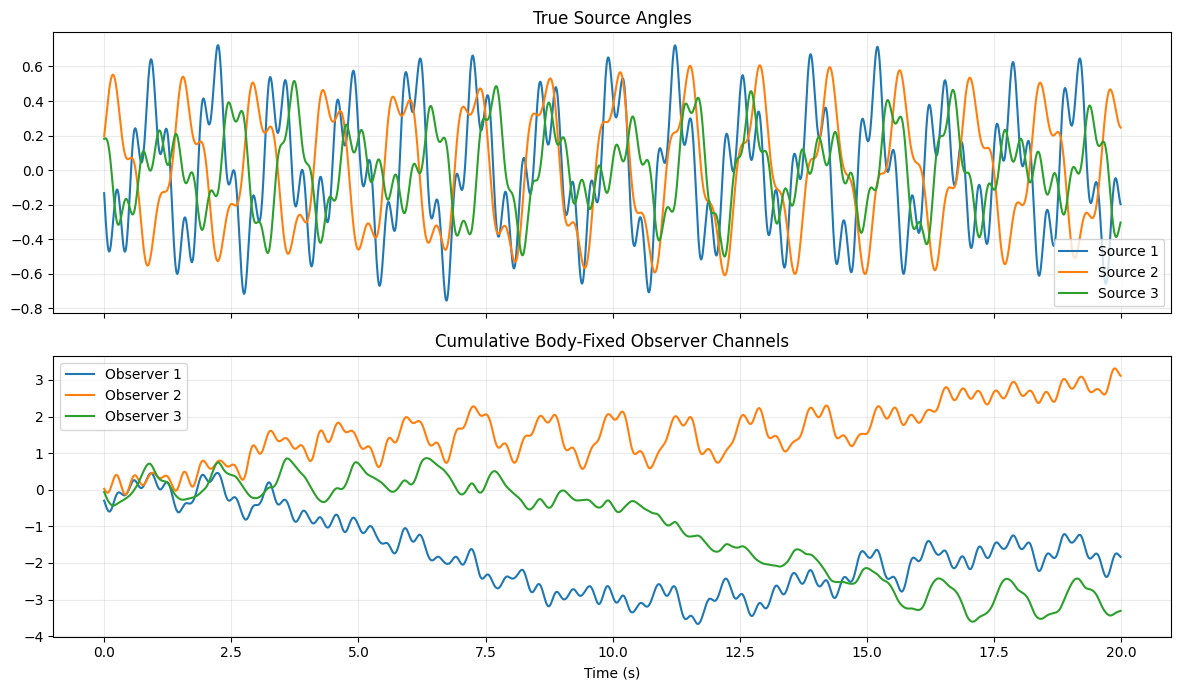

Matched source recovery


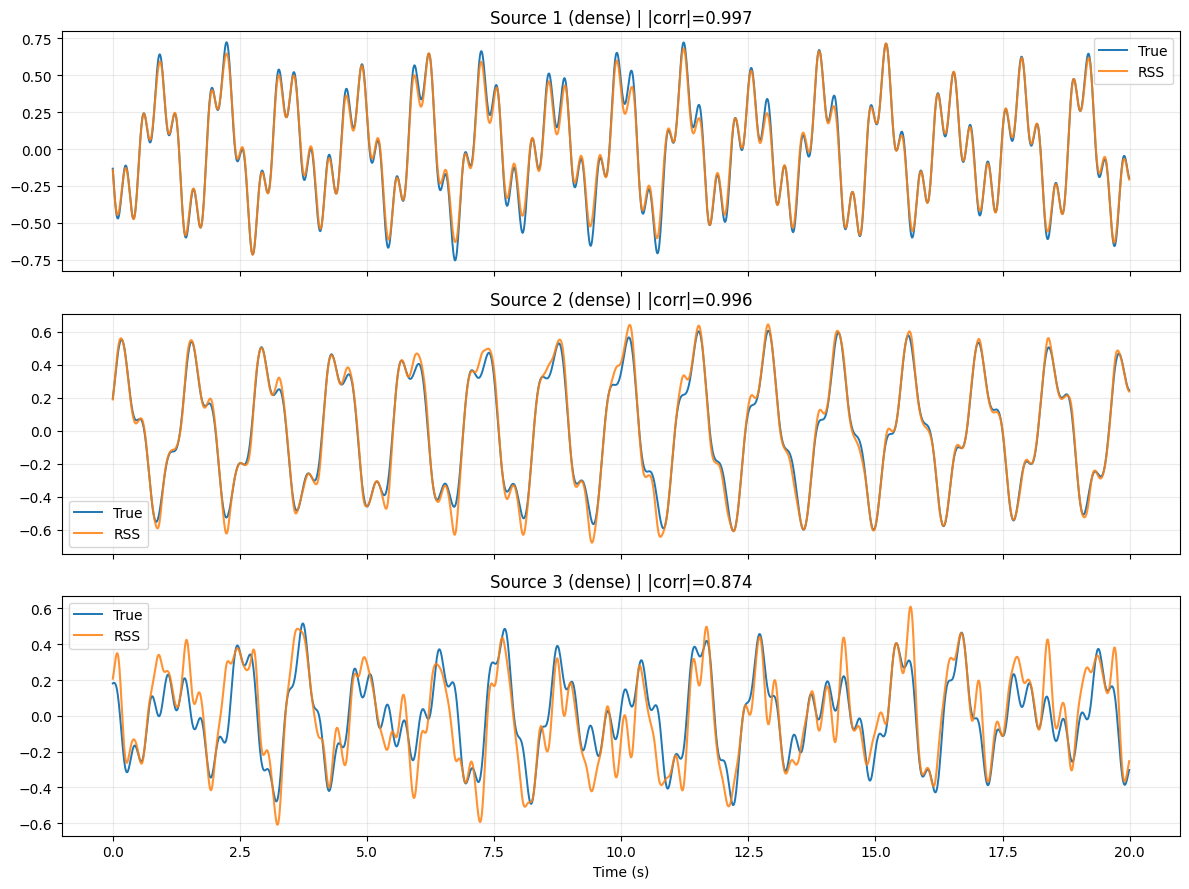

Observed versus source-composed observer angles


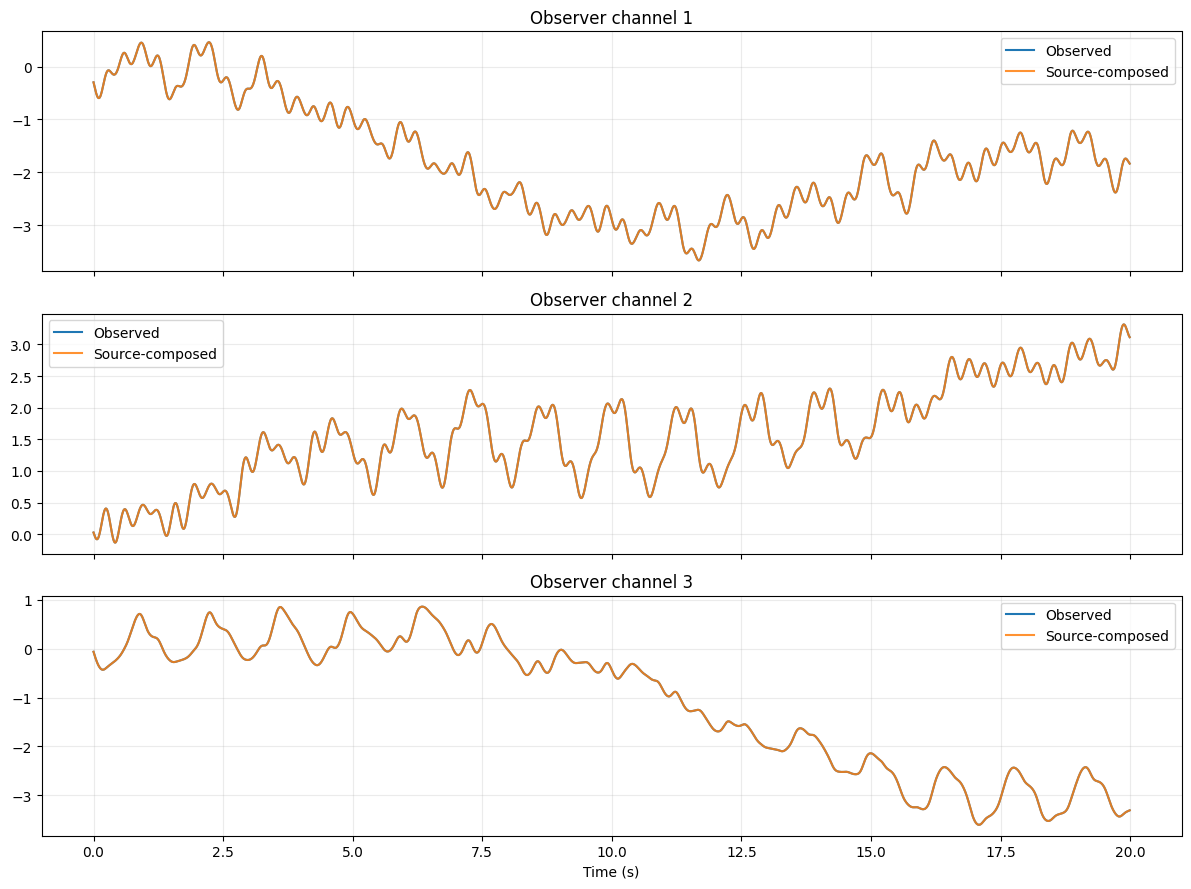

Source-axis comparison


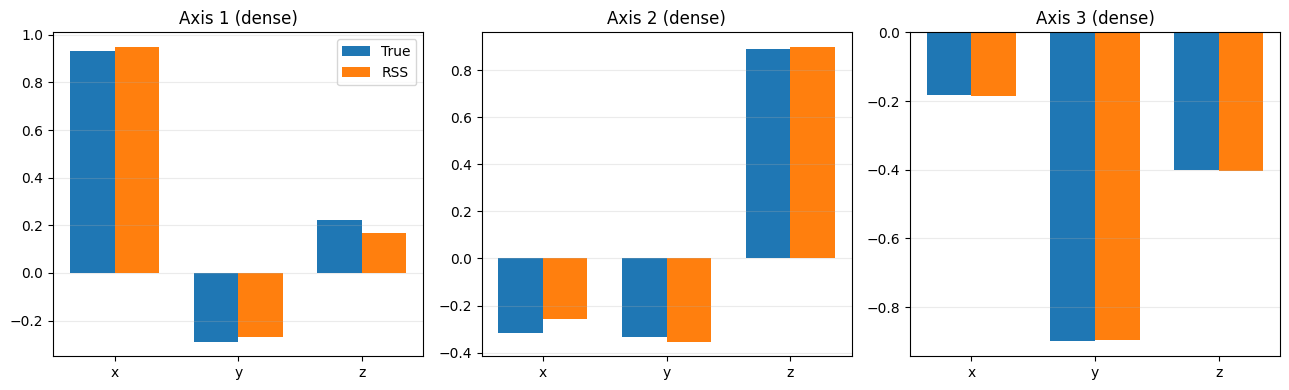

Matched permutation: (1, 0, 2)
Matched signs: [-1.  1.  1.]
Per-source absolute correlations: [0.9968 0.9963 0.8737]


In [5]:
resolved_single_config = (
    replace(single_rss_config, sample_interval_seconds=rss_result.sample_interval_seconds)
    if single_rss_config.loss_type == 'action' and single_rss_config.sample_interval_seconds is None
    else single_rss_config
)
if validation.scenario is not scenario or validation.rss_result.config != resolved_single_config:
    raise RuntimeError(
        'The scenario or RSS controls changed after fitting. Re-run section 3 before plotting section 4.'
    )
plot_builders = (
    ('Observed and true source signals', plot_observed_signals),
    ('Matched source recovery', plot_source_comparison),
    ('Observed versus source-composed observer angles', plot_observer_reconstruction),
    ('Source-axis comparison', plot_source_axis_comparison),
)
for plot_label, builder in plot_builders:
    print(plot_label)
    display_one_figure(builder(validation))
print('Matched permutation:', validation.match.permutation)
print('Matched signs:', validation.match.signs)
print('Per-source absolute correlations:', validation.match.correlations)

## 5. Batch-suite configuration

The batch MI backend is independently selectable below. GCMI and KSG require `optimizer='pso'`; B-spline and histogram MI support Adam, SGD, and PSO. Set `ksg_max_samples` to a positive integer to test deterministic KSG subsampling, or leave it as `None` for full KSG. No automatic timing is performed.

In [6]:
BATCH_ARTIFACT_ROOT = REPO_ROOT / 'notebooks' / 'artifacts' / 'rss_validation'
RUN_STANDARD_FAMILY_SUITE = True
RUN_STRESS_SUITE = True
RUN_FORMAL_EXPERIMENT_SUITE = True
batch_study_config = BatchStudyConfig()
formal_cases_per_family = 50
formal_base_seed = 20000
formal_study_config = replace(
    batch_study_config, standard_cases_per_family=formal_cases_per_family,
)
batch_sim_config = SimulationConfig(
    seed=0, T=2000,
    source_cross_correlation_limit=source_cross_correlation_limit,
)
batch_loss_type = 'lagged_cross_correlation'  # lagged_cross_correlation, mutual_information, or action
# batch_lags = (0,1,2,3,5,7,11,13,17,19,23,29,31,37,41,43,47)
batch_lags = (0,)
batch_mi_estimator = 'histogram'  # gcmi, bspline, ksg, or histogram
batch_gcmi_rank_method = 'average'
batch_bspline_bins = 6
batch_bspline_order = 3
batch_ksg_k = 4
batch_ksg_standardize = True
batch_ksg_max_samples = 1000  # None uses full KSG; set 500, 1000, etc. for a fixed subset.
batch_ksg_subsample_mode = 'fixed_random'
batch_ksg_subsample_seed = 0
batch_mi_bins = 16
batch_mi_bandwidth = 0.2
batch_action_inertias = (1.0, 1.0, 1.0)
batch_action_stiffnesses = (1.0, 1.0, 1.0)
batch_rss_config = RSSConfig(
    loss_type=batch_loss_type,
    separation_weight=1.0,
    lags=batch_lags,
    mi_estimator=batch_mi_estimator,
    gcmi_rank_method=batch_gcmi_rank_method,
    bspline_bins=batch_bspline_bins,
    bspline_order=batch_bspline_order,
    ksg_k=batch_ksg_k,
    ksg_standardize=batch_ksg_standardize,
    ksg_max_samples=batch_ksg_max_samples,
    ksg_subsample_mode=batch_ksg_subsample_mode,
    ksg_subsample_seed=batch_ksg_subsample_seed,
    mi_bins=batch_mi_bins,
    mi_bandwidth=batch_mi_bandwidth,
    action_inertias=batch_action_inertias,
    action_stiffnesses=batch_action_stiffnesses,
    epochs=3 if QUICK_MODE else 2000,
    optimizer='pso',  # adam, sgd, or pso
    learning_rate=1e-1,
    learning_rate_end=1e-3,
    sgd_momentum=0.9,
    pso_swarm_size=200, pso_inertia=0.9,
    pso_cognitive=1.0, pso_social=1.5,
    matrix_parameterization='so3',
    # This synthetic body-fixed gyro validation generates integrated body
    # rotation channels, so we explicitly use the integrated_body_rotation path.
    observer_signal_model='integrated_body_rotation',
    initial_weight_matrix=manual_initial_weight_matrix,
    pso_seed=0,
    orthogonality_weight=0.0,
    reconstruction_weight=0.0,
    convergence_tol=0.0,  # RSS always runs the complete epoch budget.
    eps=1e-24,
    quaternion_eps=1e-24,
)
print('Batch MI estimator:', batch_rss_config.mi_estimator)
print('Batch MI unit: nats')
print('Batch GCMI rank method:', batch_rss_config.gcmi_rank_method)
print('Batch B-spline bins/order:', batch_rss_config.bspline_bins, batch_rss_config.bspline_order)
print('Batch KSG k:', batch_rss_config.ksg_k)
print('Batch KSG standardization:', batch_rss_config.ksg_standardize)
print('Batch KSG maximum samples:', batch_rss_config.ksg_max_samples)
print('Batch KSG subsampling mode/seed:', batch_rss_config.ksg_subsample_mode, batch_rss_config.ksg_subsample_seed)
batch_effective_ksg_samples = batch_sim_config.T if batch_rss_config.ksg_max_samples is None else min(batch_sim_config.T, batch_rss_config.ksg_max_samples)
print('Batch KSG effective sample count:', batch_effective_ksg_samples)
print('Batch initial recovery/weight matrix:')

print(batch_rss_config.resolved_initial_matrix)

Batch MI estimator: histogram
Batch MI unit: nats
Batch GCMI rank method: average
Batch B-spline bins/order: 6 3
Batch KSG k: 4
Batch KSG standardization: True
Batch KSG maximum samples: 1000
Batch KSG subsampling mode/seed: fixed_random 0
Batch KSG effective sample count: 1000
Batch initial recovery/weight matrix:
[[-0.4779 -0.5421 -0.6911]
 [-0.5984  0.777  -0.1956]
 [ 0.643   0.3201 -0.6957]]


## 6. Standard 20-case family suite

Standard case 1/20: harmonic_01
Standard case 2/20: harmonic_02
Standard case 3/20: harmonic_03
Standard case 4/20: harmonic_04
Standard case 5/20: harmonic_05
Standard case 6/20: filtered_noise_01
Standard case 7/20: filtered_noise_02
Standard case 8/20: filtered_noise_03
Standard case 9/20: filtered_noise_04
Standard case 10/20: filtered_noise_05
Standard case 11/20: chirp_modulated_01
Standard case 12/20: chirp_modulated_02
Standard case 13/20: chirp_modulated_03
Standard case 14/20: chirp_modulated_04
Standard case 15/20: chirp_modulated_05
Standard case 16/20: piecewise_transient_01
Standard case 17/20: piecewise_transient_02
Standard case 18/20: piecewise_transient_03
Standard case 19/20: piecewise_transient_04
Standard case 20/20: piecewise_transient_05


,family,source_1_realized_amplitude_rad,source_1_realized_frequency_hz,source_2_realized_amplitude_rad,source_2_realized_frequency_hz,source_3_realized_amplitude_rad,source_3_realized_frequency_hz,mean_requested_amplitude_rad,mean_requested_frequency_hz,rss_bspline_bins,...,rss_best_loss,rss_best_separation_loss,rss_best_normalized_separation_loss,rss_terminal_loss,rss_best_reconstruction_loss,rss_best_normalized_reconstruction_loss,rss_best_epoch,matrix_condition_number,matrix_orthogonality_error,matrix_determinant
0,chirp_modulated,0.744513,1.750661,0.765285,1.963955,0.827863,1.642196,NaN,NaN,6.0,...,3.101415e-07,3.101415e-07,0.000002,3.101415e-07,2.216783e-32,0.0,725.4,1.0,9.671011e-16,1.0
1,filtered_noise,0.773504,0.194114,0.715058,0.511905,0.852417,0.871032,NaN,NaN,6.0,...,2.740045e-06,2.740045e-06,0.000107,2.740045e-06,6.946770e-33,0.0,829.2,1.0,7.570053e-16,1.0
2,harmonic,0.727762,0.945767,0.698595,0.489749,0.755849,0.589947,NaN,NaN,6.0,...,1.635969e-07,1.635969e-07,0.000005,1.635969e-07,1.900140e-32,0.0,827.6,1.0,8.439452e-16,1.0
3,piecewise_transient,0.804202,0.223545,0.830578,0.215939,0.770230,0.309193,NaN,NaN,6.0,...,5.243225e-06,5.243225e-06,0.000072,5.243225e-06,4.396549e-32,0.0,771.4,1.0,1.149254e-15,1.0


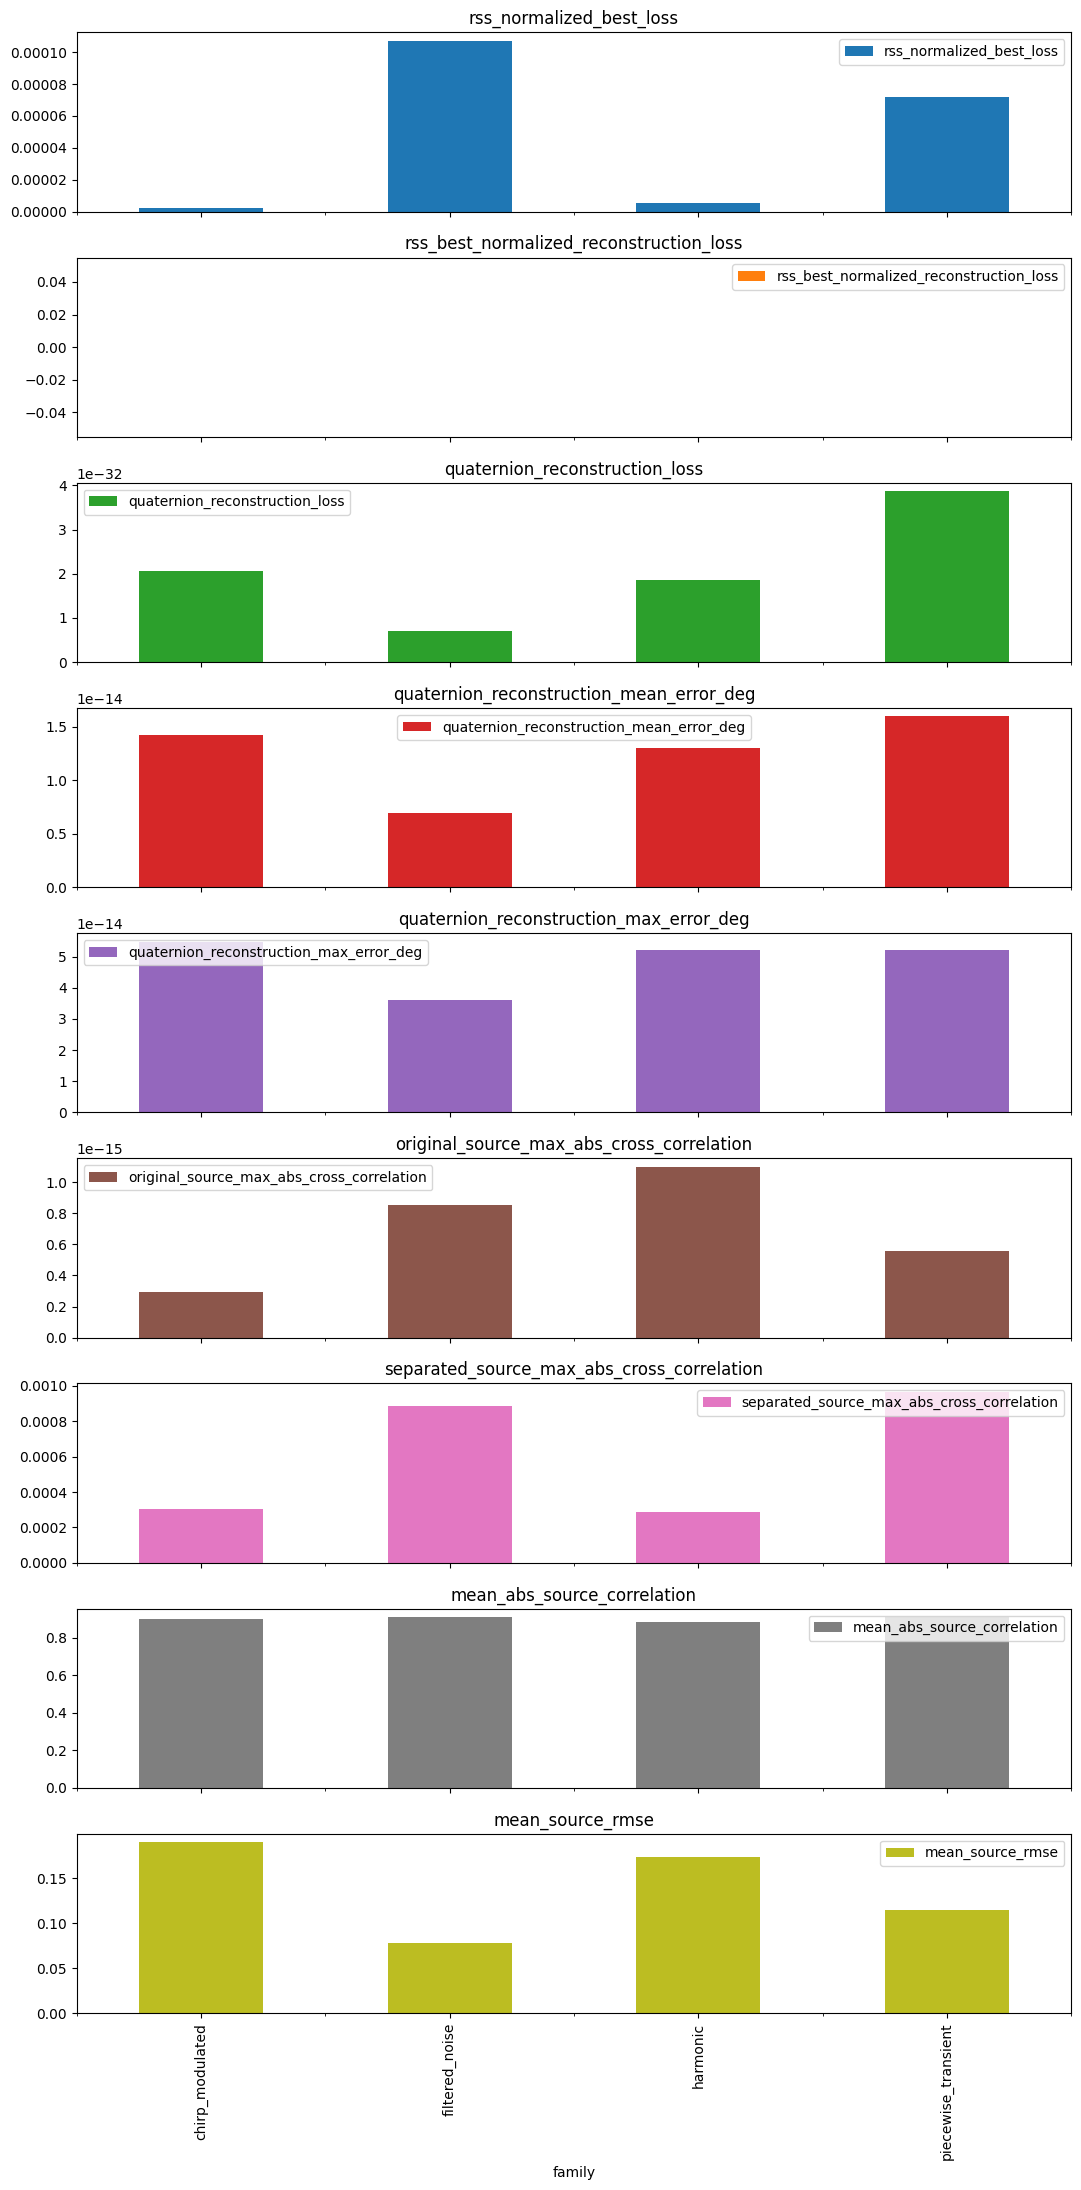

In [7]:
standard_results = []
if RUN_STANDARD_FAMILY_SUITE:
    standard_specs = create_standard_case_specs(batch_study_config)
    if QUICK_MODE:
        standard_specs = standard_specs[:2]
    for index, spec in enumerate(standard_specs, start=1):
        case = generate_family_scenario(spec, batch_sim_config, batch_study_config)
        validate_zero_mean_sources(case)
        result = run_validation_for_scenario(case, batch_rss_config)
        export_validation_case_artifacts(result, BATCH_ARTIFACT_ROOT / 'standard_families' / 'cases' / spec.family / spec.case_id)
        standard_results.append(result)
        print(f'Standard case {index}/{len(standard_specs)}: {spec.case_id}')
    standard_metrics = build_metrics_frame(standard_results)
    standard_summary = summarize_standard_suite(standard_metrics)
    summary_root = BATCH_ARTIFACT_ROOT / 'standard_families' / 'summary'
    summary_root.mkdir(parents=True, exist_ok=True)
    standard_metrics.to_csv(summary_root / 'per_case_metrics.csv', index=False)
    standard_summary.to_csv(summary_root / 'family_average_metrics.csv', index=False)
    display(standard_summary)
    summary_axes = standard_summary.plot.bar(x='family', y=['rss_normalized_best_loss', 'rss_best_normalized_reconstruction_loss', 'quaternion_reconstruction_loss', 'quaternion_reconstruction_mean_error_deg', 'quaternion_reconstruction_max_error_deg', 'original_source_max_abs_cross_correlation', 'separated_source_max_abs_cross_correlation', 'mean_abs_source_correlation', 'mean_source_rmse'], subplots=True, figsize=(11, 22))
    summary_figure = np.asarray(summary_axes).reshape(-1)[0].figure
    summary_figure.tight_layout()
    display_one_figure(summary_figure)

## 7. Eight-case large-rotation stress suite

Stress case 1/8: harmonic_stress_01
Stress case 2/8: harmonic_stress_02
Stress case 3/8: harmonic_stress_03
Stress case 4/8: harmonic_stress_04
Stress case 5/8: harmonic_stress_05
Stress case 6/8: harmonic_stress_06
Stress case 7/8: harmonic_stress_07
Stress case 8/8: harmonic_stress_08


,family,case_id,seed,frame_count,amplitude_tier,stress_peak_angle_rad,composition,replicate_index,source_roles,simulation_observation_model,...,rss_best_loss,rss_best_separation_loss,rss_best_normalized_separation_loss,rss_terminal_loss,rss_best_reconstruction_loss,rss_best_normalized_reconstruction_loss,rss_best_epoch,matrix_condition_number,matrix_orthogonality_error,matrix_determinant
0,harmonic,harmonic_stress_01,7300,720,high,0.55,triple_rotation,None,dense|dense|dense,body_fixed_gyro,...,1.445117e-30,1.445117e-30,6.995600e-29,1.445117e-30,1.042212e-32,0.0,780.0,1.0,4.258175e-16,1.0
1,harmonic,harmonic_stress_02,7331,840,high,0.85,triple_rotation,None,dense|dense|dense,body_fixed_gyro,...,8.256330e-29,8.256330e-29,1.157345e-26,8.256330e-29,2.222344e-32,0.0,755.0,1.0,3.154746e-16,1.0
2,harmonic,harmonic_stress_03,7362,960,high,1.15,triple_rotation,None,dense|dense|dense,body_fixed_gyro,...,3.045150e-34,3.045150e-34,4.926986e-33,3.045150e-34,1.695668e-32,0.0,665.0,1.0,2.979857e-16,1.0
3,harmonic,harmonic_stress_04,7393,1080,high,1.45,triple_rotation,None,dense|dense|dense,body_fixed_gyro,...,2.985645e-33,2.985645e-33,7.577527e-32,2.985645e-33,5.640692e-32,0.0,638.0,1.0,1.330514e-15,1.0
4,harmonic,harmonic_stress_05,7424,720,high,1.75,triple_rotation,None,dense|dense|dense,body_fixed_gyro,...,4.655480e-34,4.655480e-34,2.859412e-32,4.655480e-34,6.288322e-32,0.0,606.0,1.0,4.436689e-16,1.0
5,harmonic,harmonic_stress_06,7455,840,high,2.05,triple_rotation,None,dense|dense|dense,body_fixed_gyro,...,1.452297e-35,1.452297e-35,5.519225e-34,1.452297e-35,7.712755e-32,0.0,665.0,1.0,6.163490e-16,1.0
6,harmonic,harmonic_stress_07,7486,960,high,2.35,triple_rotation,None,dense|dense|dense,body_fixed_gyro,...,4.105558e-07,4.105558e-07,1.901128e-04,4.105558e-07,1.274656e-31,0.0,2000.0,1.0,4.207228e-16,1.0
7,harmonic,harmonic_stress_08,7517,1080,high,2.65,triple_rotation,None,dense|dense|dense,body_fixed_gyro,...,2.353770e-33,2.353770e-33,5.888843e-32,2.353770e-33,2.028915e-31,0.0,657.0,1.0,4.686121e-16,1.0


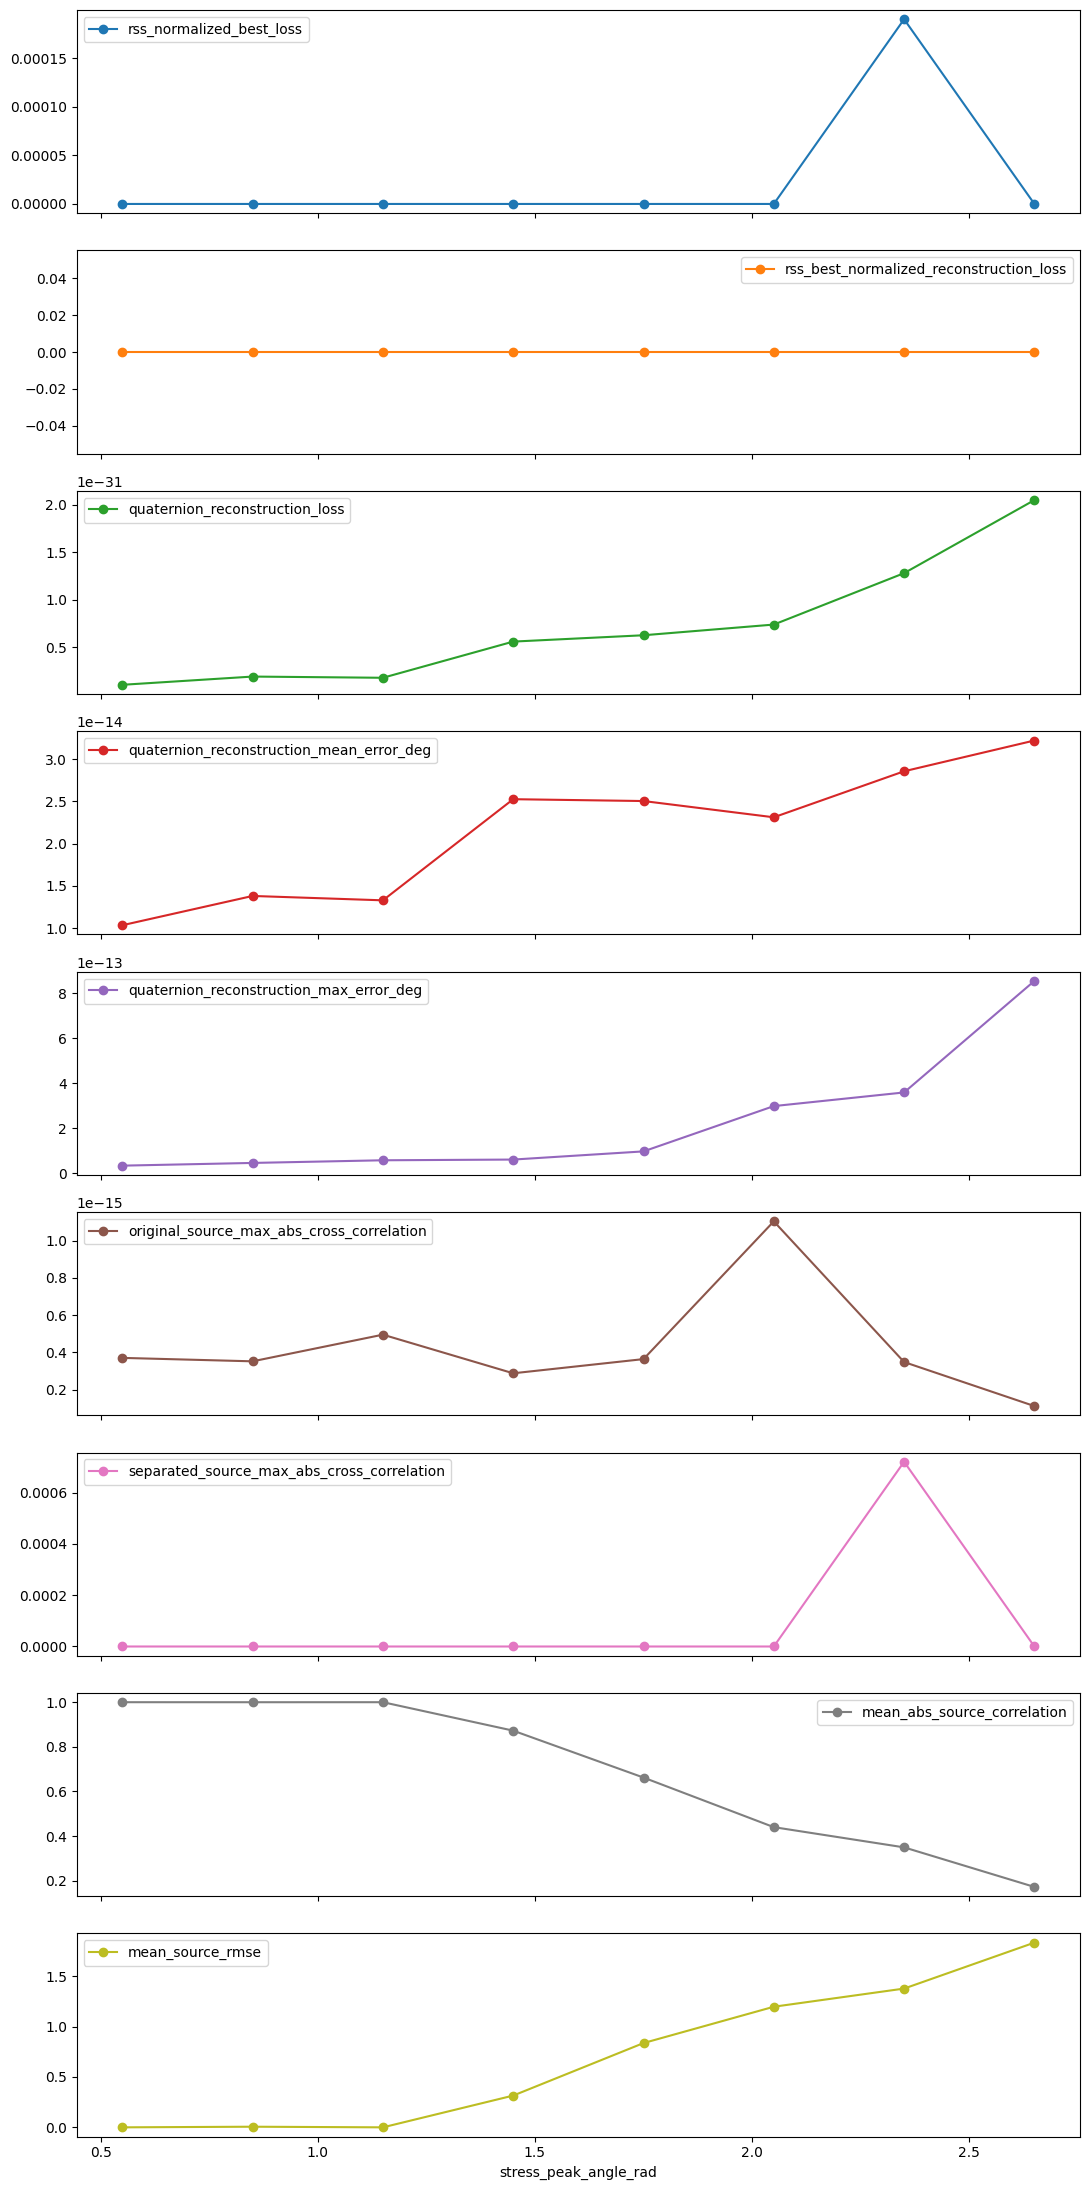

In [8]:
stress_results = []
if RUN_STRESS_SUITE:
    stress_specs = create_stress_case_specs(batch_study_config)
    if QUICK_MODE:
        stress_specs = stress_specs[:2]
    for index, spec in enumerate(stress_specs, start=1):
        case = generate_family_scenario(spec, batch_sim_config, batch_study_config)
        validate_zero_mean_sources(case)
        result = run_validation_for_scenario(case, batch_rss_config)
        export_validation_case_artifacts(result, BATCH_ARTIFACT_ROOT / 'large_rotation_stress' / 'cases' / spec.case_id)
        stress_results.append(result)
        print(f'Stress case {index}/{len(stress_specs)}: {spec.case_id}')
    stress_metrics = summarize_stress_suite(build_metrics_frame(stress_results))
    stress_root = BATCH_ARTIFACT_ROOT / 'large_rotation_stress' / 'summary'
    stress_root.mkdir(parents=True, exist_ok=True)
    stress_metrics.to_csv(stress_root / 'stress_metrics.csv', index=False)
    display(stress_metrics)
    stress_axes = stress_metrics.plot(x='stress_peak_angle_rad', y=['rss_normalized_best_loss', 'rss_best_normalized_reconstruction_loss', 'quaternion_reconstruction_loss', 'quaternion_reconstruction_mean_error_deg', 'quaternion_reconstruction_max_error_deg', 'original_source_max_abs_cross_correlation', 'separated_source_max_abs_cross_correlation', 'mean_abs_source_correlation', 'mean_source_rmse'], marker='o', subplots=True, figsize=(11, 22))
    stress_figure = np.asarray(stress_axes).reshape(-1)[0].figure
    stress_figure.tight_layout()
    display_one_figure(stress_figure)

## 8. Formal 200-case three-source family experiment

Formal case 1/200: formal_harmonic_01
Formal case 2/200: formal_harmonic_02
Formal case 3/200: formal_harmonic_03
Formal case 4/200: formal_harmonic_04
Formal case 5/200: formal_harmonic_05
Formal case 6/200: formal_harmonic_06
Formal case 7/200: formal_harmonic_07
Formal case 8/200: formal_harmonic_08
Formal case 9/200: formal_harmonic_09
Formal case 10/200: formal_harmonic_10
Formal case 11/200: formal_harmonic_11
Formal case 12/200: formal_harmonic_12
Formal case 13/200: formal_harmonic_13
Formal case 14/200: formal_harmonic_14
Formal case 15/200: formal_harmonic_15
Formal case 16/200: formal_harmonic_16
Formal case 17/200: formal_harmonic_17
Formal case 18/200: formal_harmonic_18
Formal case 19/200: formal_harmonic_19
Formal case 20/200: formal_harmonic_20
Formal case 21/200: formal_harmonic_21
Formal case 22/200: formal_harmonic_22
Formal case 23/200: formal_harmonic_23
Formal case 24/200: formal_harmonic_24
Formal case 25/200: formal_harmonic_25
Formal case 26/200: formal_harmoni

,family,metric,count,mean,std,min,p05,p25,median,p75,p95,max
0,harmonic,true_rss_abs_correlation,150,0.916285,0.102585,6.078032e-01,6.919471e-01,0.864449,0.956835,0.998677,1.000000,1.000000
1,harmonic,source_mse_rad2,150,0.044919,0.065205,4.349703e-31,2.096258e-29,0.000351,0.010564,0.073124,0.198110,0.283945
2,harmonic,source_rmse_rad,150,0.151537,0.148672,6.595228e-16,4.540465e-15,0.018623,0.102778,0.270413,0.445090,0.532865
3,harmonic,source_mae_rad,150,0.114950,0.111814,5.333577e-16,3.877701e-15,0.015423,0.083114,0.208642,0.346675,0.379734
4,harmonic,source_max_abs_error_rad,150,0.476093,0.489184,1.443290e-15,9.664491e-15,0.050117,0.315200,0.824863,1.407277,2.192039
5,harmonic,source_relative_rmse,150,0.326098,0.275572,2.709261e-15,1.171713e-14,0.051428,0.293602,0.529935,0.820322,0.947874
6,harmonic,source_r2,150,0.818226,0.227201,1.015349e-01,3.270091e-01,0.719126,0.913798,0.997349,1.000000,1.000000
7,harmonic,source_snr_db,150,30.997139,48.038999,4.649881e-01,1.720728e+00,5.516209,10.644828,25.785562,149.731407,152.913596
8,harmonic,source_axis_error_deg,150,11.379261,12.321888,0.000000e+00,0.000000e+00,1.180043,6.719442,16.930285,37.823399,46.782318
9,filtered_noise,true_rss_abs_correlation,150,0.929958,0.093679,5.814250e-01,7.321046e-01,0.901151,0.978706,0.997278,1.000000,1.000000


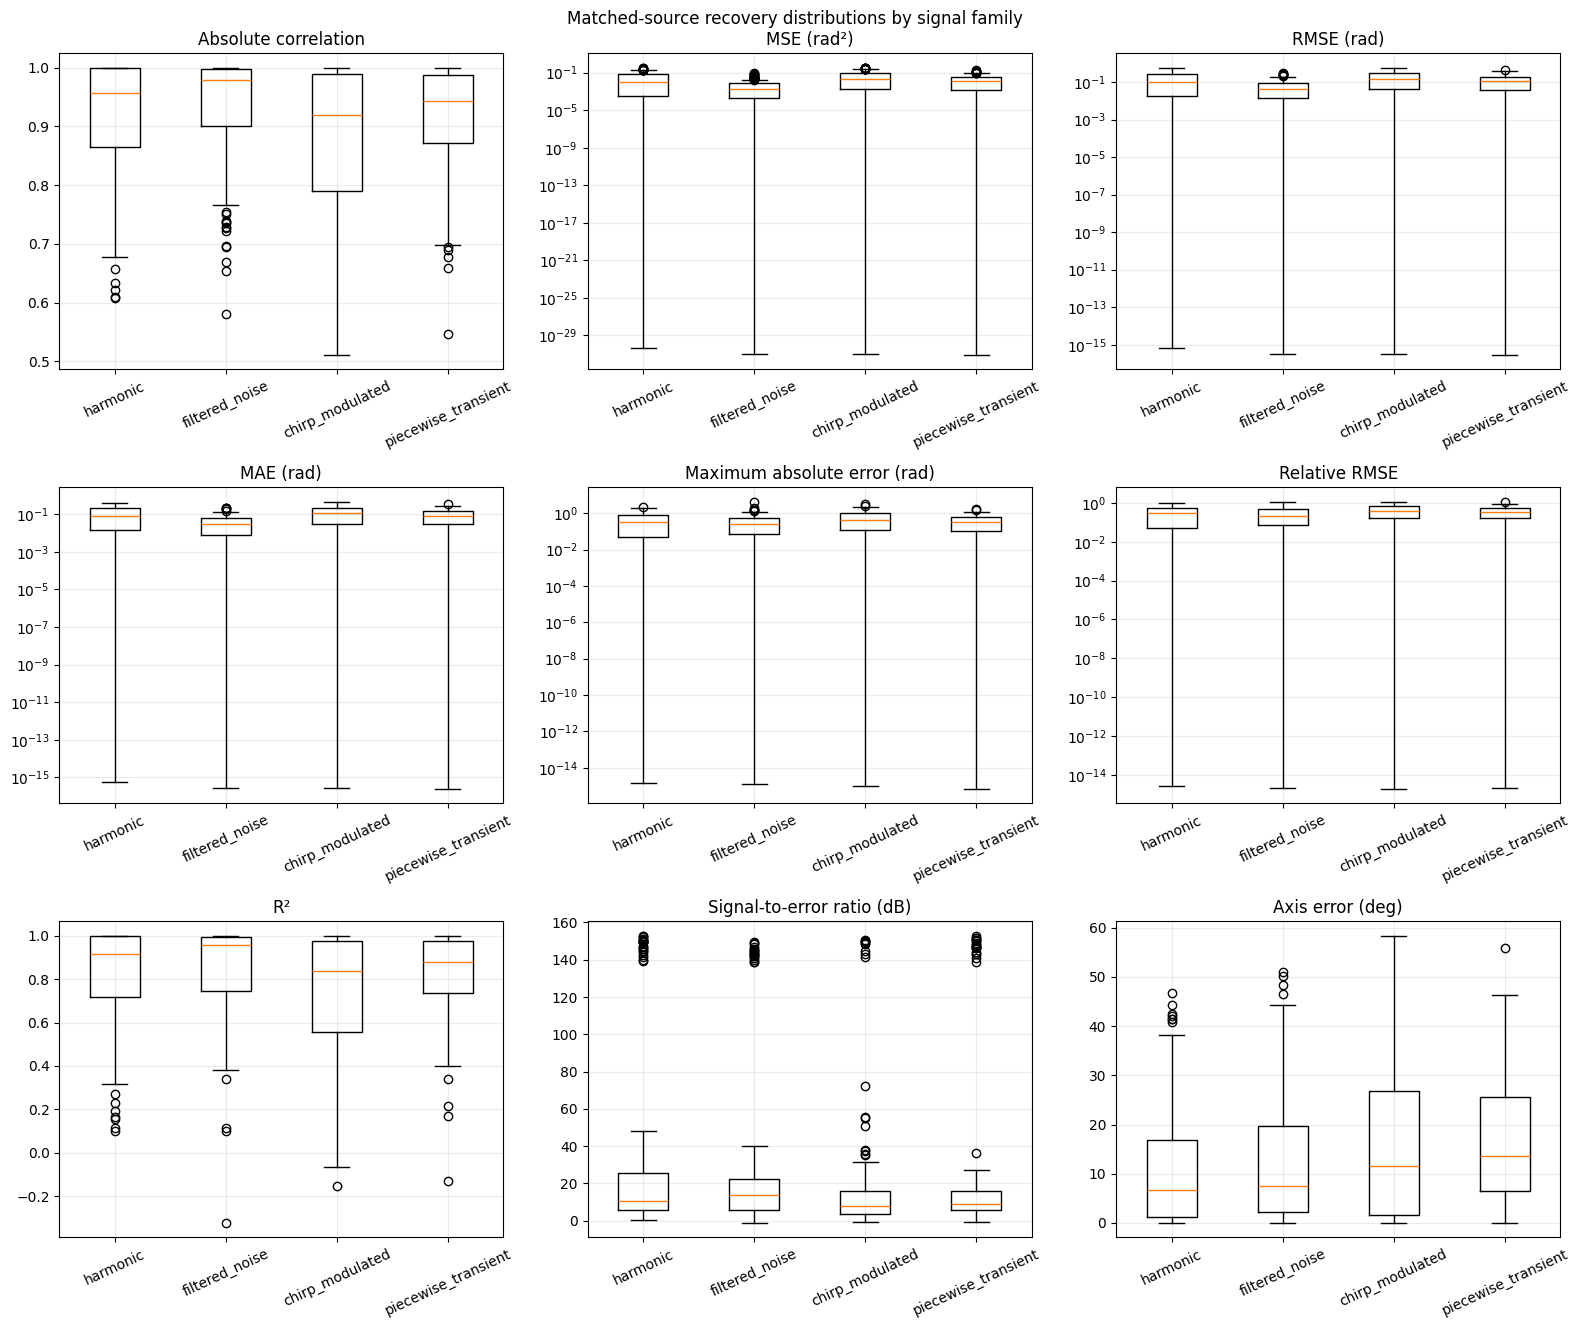

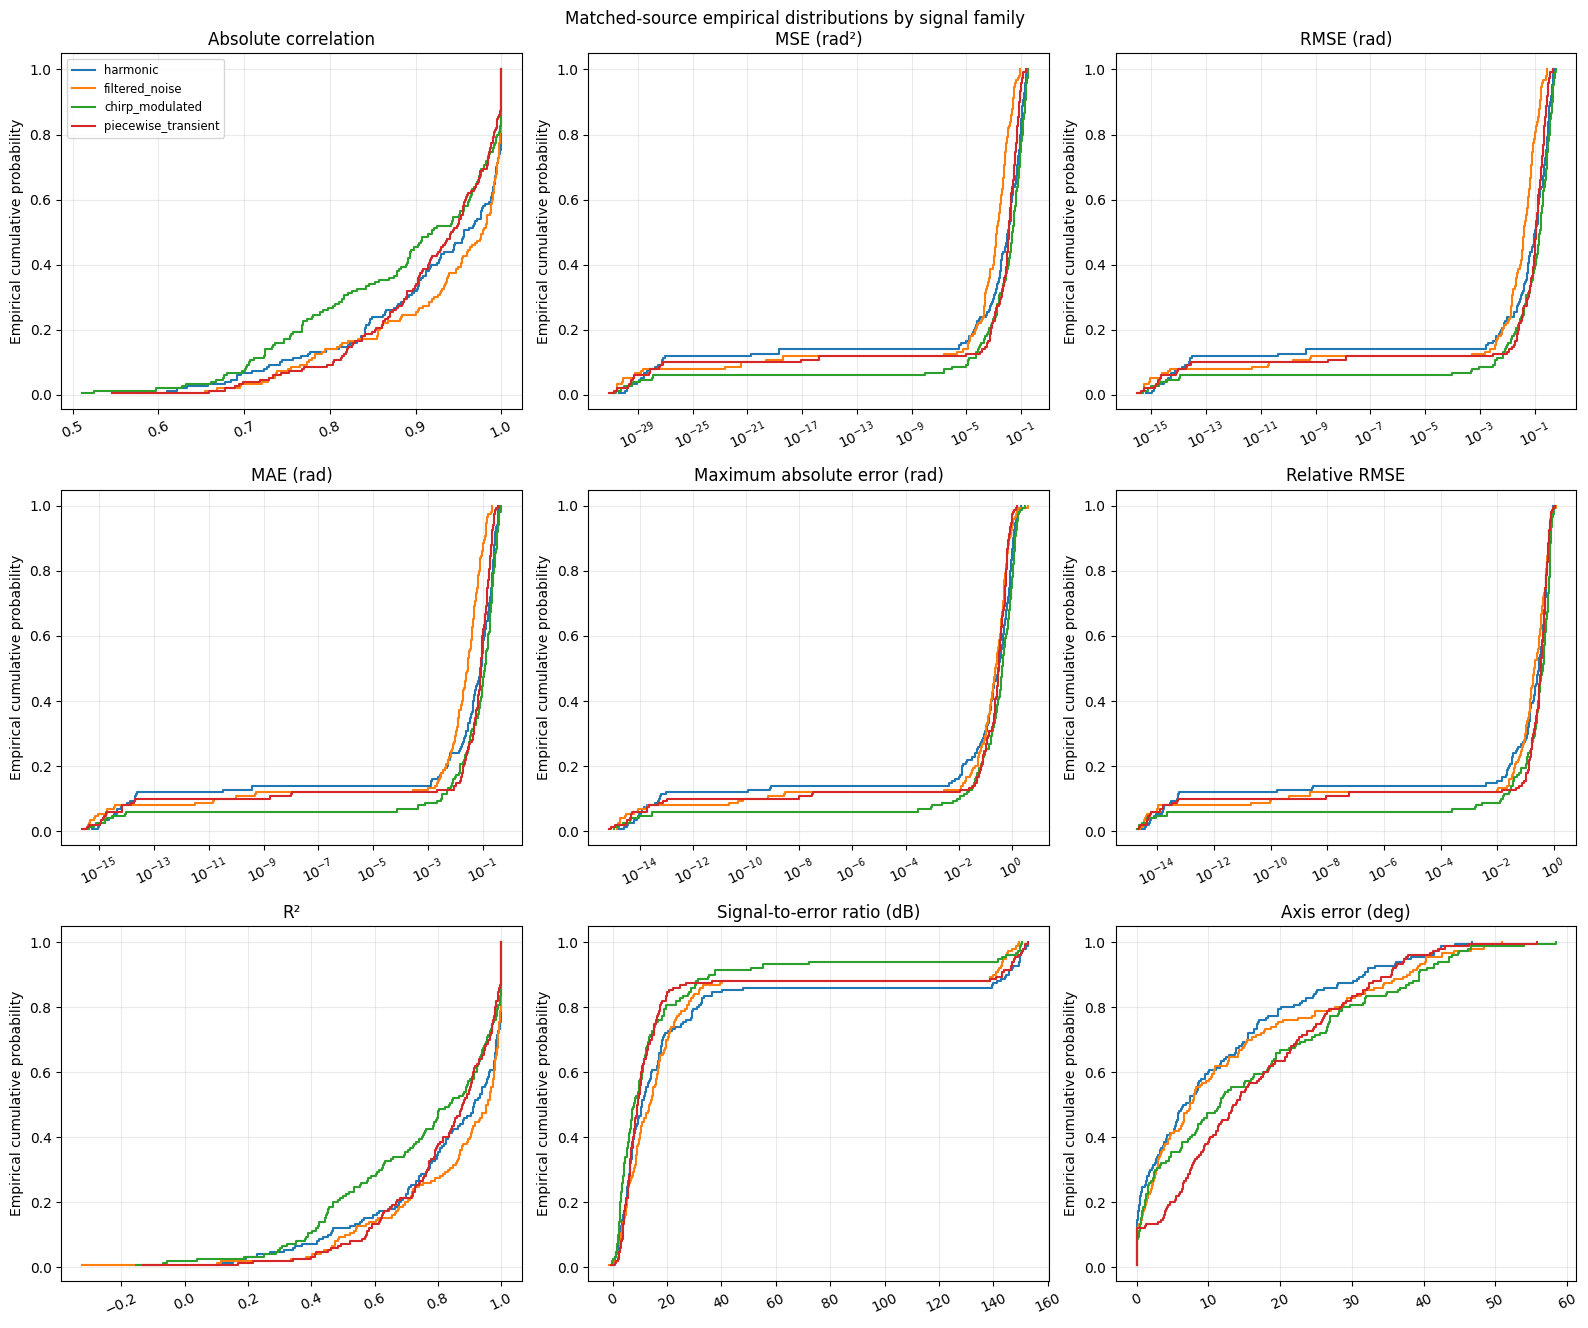

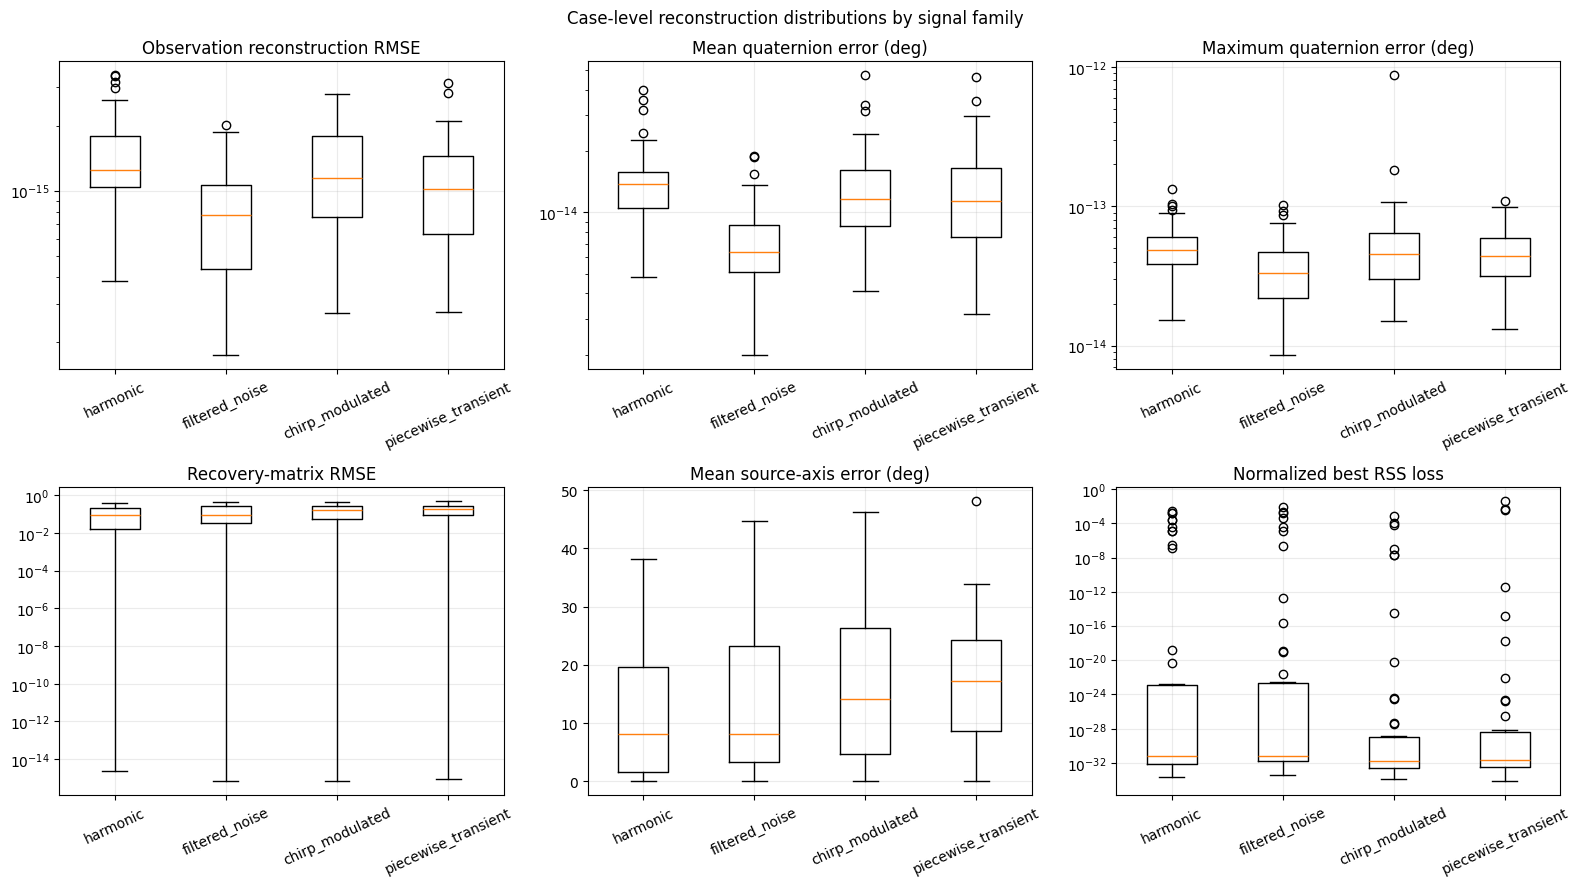

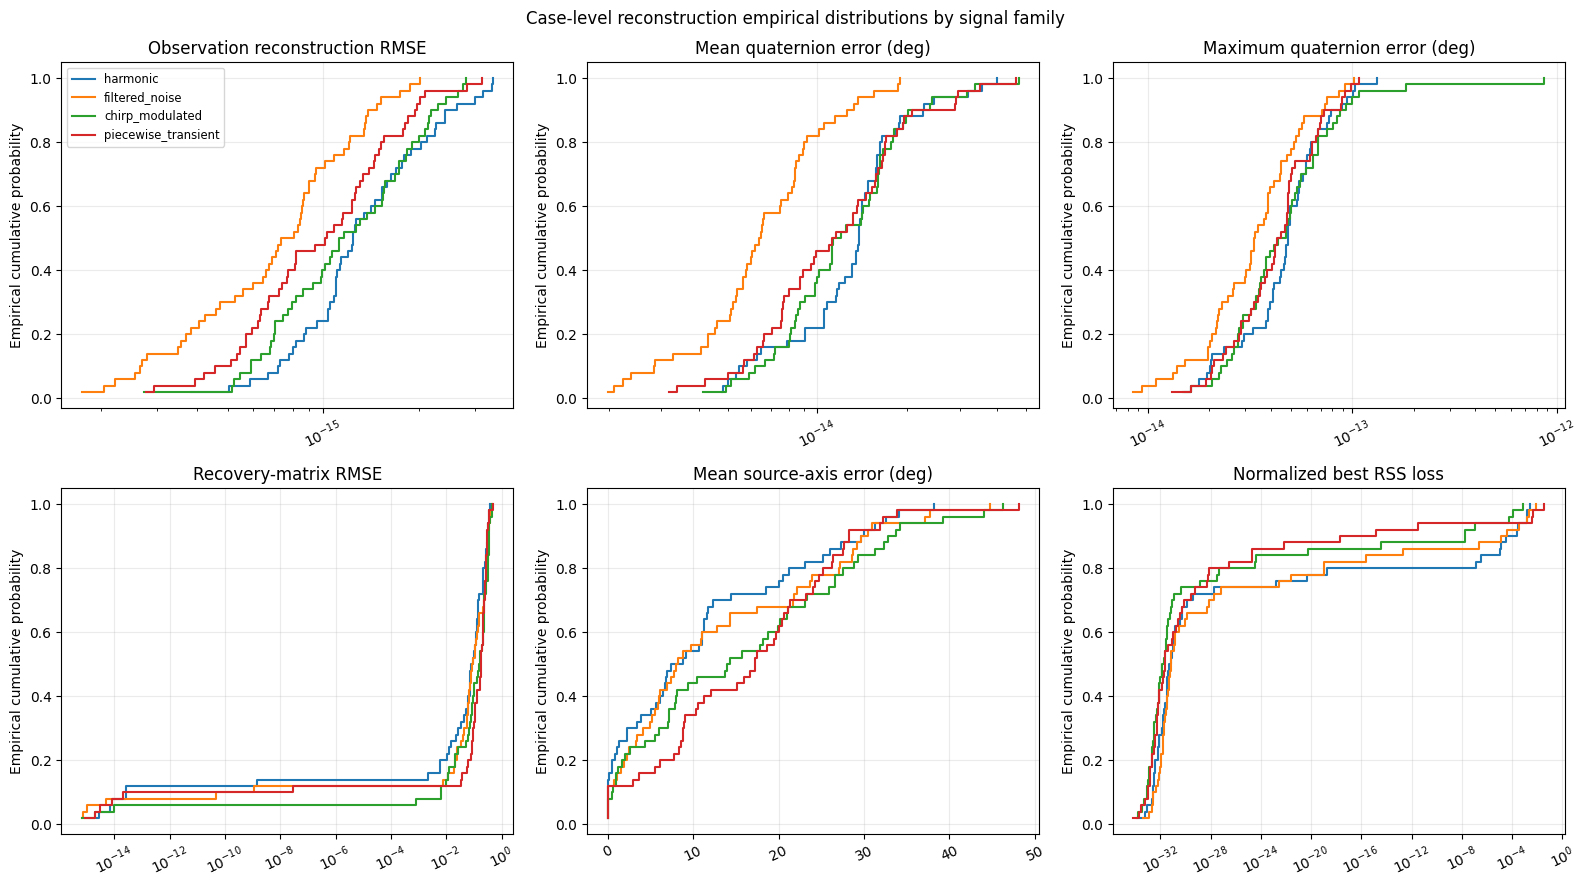

In [9]:
formal_results = []
if RUN_FORMAL_EXPERIMENT_SUITE:
    formal_specs = create_standard_case_specs(
        formal_study_config, base_seed=formal_base_seed, case_id_prefix='formal_',
    )
    standard_seed_set = {spec.seed for spec in create_standard_case_specs(batch_study_config)}
    formal_family_counts = pd.Series([spec.family for spec in formal_specs]).value_counts()
    if len(formal_specs) != 200 or set(formal_family_counts.index) != set(formal_study_config.standard_families):
        raise RuntimeError('The formal suite must contain exactly four standard signal families.')
    if not (formal_family_counts == formal_cases_per_family).all():
        raise RuntimeError('The formal suite must contain exactly 50 cases per signal family.')
    if len({spec.case_id for spec in formal_specs}) != 200 or len({spec.seed for spec in formal_specs}) != 200:
        raise RuntimeError('Formal case IDs and seeds must be unique.')
    if standard_seed_set & {spec.seed for spec in formal_specs}:
        raise RuntimeError('Formal seeds must not overlap the standard 20-case suite.')
    if QUICK_MODE:
        formal_specs = [
            next(spec for spec in formal_specs if spec.family == family)
            for family in formal_study_config.standard_families
        ]
    for index, spec in enumerate(formal_specs, start=1):
        case = generate_family_scenario(spec, batch_sim_config, formal_study_config)
        validate_zero_mean_sources(case)
        if case.source_roles != ('dense', 'dense', 'dense') or case.active_source_indices != (0, 1, 2):
            raise RuntimeError(f'Formal case {spec.case_id} does not contain three active rotation sources.')
        result = run_validation_for_scenario(case, batch_rss_config)
        case_root = BATCH_ARTIFACT_ROOT / 'formal_experiments' / 'cases' / spec.family / spec.case_id
        export_validation_case_artifacts(result, case_root, include_plots=False)
        formal_results.append(result)
        print(f'Formal case {index}/{len(formal_specs)}: {spec.case_id}')

    formal_metrics = build_metrics_frame(formal_results)
    formal_source_metrics = build_source_metrics_frame(formal_results)
    formal_case_metric_columns = (
        'mean_abs_source_correlation', 'mean_source_mse', 'mean_source_rmse',
        'mean_source_mae', 'max_source_abs_error', 'mean_source_relative_rmse',
        'mean_source_r2', 'mean_source_snr_db', 'mean_axis_error_deg',
        'observation_reconstruction_rmse', 'quaternion_reconstruction_mean_error_deg',
        'quaternion_reconstruction_max_error_deg', 'recovery_matrix_rmse',
        'rss_normalized_best_loss',
    )
    formal_source_metric_columns = (
        'true_rss_abs_correlation', 'source_mse_rad2', 'source_rmse_rad',
        'source_mae_rad', 'source_max_abs_error_rad', 'source_relative_rmse',
        'source_r2', 'source_snr_db', 'source_axis_error_deg',
    )
    formal_family_case_distributions = describe_metric_distributions(
        formal_metrics, group_columns=('family',), metric_columns=formal_case_metric_columns,
    )
    formal_family_source_distributions = describe_metric_distributions(
        formal_source_metrics, group_columns=('family',), metric_columns=formal_source_metric_columns,
    )
    formal_family_source_index_distributions = describe_metric_distributions(
        formal_source_metrics, group_columns=('family', 'source_index'), metric_columns=formal_source_metric_columns,
    )
    formal_root = BATCH_ARTIFACT_ROOT / 'formal_experiments' / 'summary'
    formal_root.mkdir(parents=True, exist_ok=True)
    formal_metrics.to_csv(formal_root / 'per_case_metrics.csv', index=False)
    formal_source_metrics.to_csv(formal_root / 'per_source_metrics.csv', index=False)
    formal_family_case_distributions.to_csv(formal_root / 'family_case_metric_distributions.csv', index=False)
    formal_family_source_distributions.to_csv(formal_root / 'family_source_metric_distributions.csv', index=False)
    formal_family_source_index_distributions.to_csv(formal_root / 'family_source_index_metric_distributions.csv', index=False)
    display(formal_family_source_distributions)

    family_order = list(formal_study_config.standard_families)
    source_metric_labels = {
        'true_rss_abs_correlation': 'Absolute correlation',
        'source_mse_rad2': 'MSE (rad²)', 'source_rmse_rad': 'RMSE (rad)',
        'source_mae_rad': 'MAE (rad)', 'source_max_abs_error_rad': 'Maximum absolute error (rad)',
        'source_relative_rmse': 'Relative RMSE', 'source_r2': 'R²',
        'source_snr_db': 'Signal-to-error ratio (dB)', 'source_axis_error_deg': 'Axis error (deg)',
    }
    case_metric_labels = {
        'observation_reconstruction_rmse': 'Observation reconstruction RMSE',
        'quaternion_reconstruction_mean_error_deg': 'Mean quaternion error (deg)',
        'quaternion_reconstruction_max_error_deg': 'Maximum quaternion error (deg)',
        'recovery_matrix_rmse': 'Recovery-matrix RMSE',
        'mean_axis_error_deg': 'Mean source-axis error (deg)',
        'rss_normalized_best_loss': 'Normalized best RSS loss',
    }
    logarithmic_metrics = {
        'source_mse_rad2', 'source_rmse_rad', 'source_mae_rad',
        'source_max_abs_error_rad', 'source_relative_rmse',
        'observation_reconstruction_rmse', 'quaternion_reconstruction_mean_error_deg',
        'quaternion_reconstruction_max_error_deg', 'recovery_matrix_rmse',
        'mean_axis_error_deg', 'rss_normalized_best_loss',
    }

    def plot_family_metric_grid(frame, metric_labels, *, kind, title, output_path):
        metric_names = list(metric_labels)
        column_count = 3
        row_count = int(np.ceil(len(metric_names) / column_count))
        figure, axes = plt.subplots(row_count, column_count, figsize=(16, 4.5 * row_count), squeeze=False)
        for axis, metric in zip(axes.ravel(), metric_names):
            family_values = [
                frame.loc[frame['family'] == family, metric].dropna().to_numpy(dtype=float)
                for family in family_order
            ]
            if kind == 'box':
                try:
                    axis.boxplot(family_values, tick_labels=family_order, showfliers=True)
                except TypeError:  # Matplotlib < 3.9
                    axis.boxplot(family_values, labels=family_order, showfliers=True)
                if metric in logarithmic_metrics and all(np.all(values > 0.0) for values in family_values):
                    axis.set_yscale('log')
            else:
                for family, values in zip(family_order, family_values):
                    ordered = np.sort(values)
                    probabilities = np.arange(1, ordered.size + 1) / ordered.size
                    axis.step(ordered, probabilities, where='post', label=family)
                if metric in logarithmic_metrics and all(np.all(values > 0.0) for values in family_values):
                    axis.set_xscale('log')
                axis.set_ylabel('Empirical cumulative probability')
            axis.set_title(metric_labels[metric])
            axis.tick_params(axis='x', labelrotation=25)
            axis.grid(True, alpha=0.25)
        for axis in axes.ravel()[len(metric_names):]:
            axis.set_visible(False)
        if kind == 'ecdf':
            axes.ravel()[0].legend(fontsize='small')
        figure.suptitle(title)
        figure.tight_layout()
        figure.savefig(output_path, dpi=150, bbox_inches='tight')
        display_one_figure(figure)

    plot_family_metric_grid(formal_source_metrics, source_metric_labels, kind='box', title='Matched-source recovery distributions by signal family', output_path=formal_root / 'family_source_metric_boxplots.png')
    plot_family_metric_grid(formal_source_metrics, source_metric_labels, kind='ecdf', title='Matched-source empirical distributions by signal family', output_path=formal_root / 'family_source_metric_ecdfs.png')
    plot_family_metric_grid(formal_metrics, case_metric_labels, kind='box', title='Case-level reconstruction distributions by signal family', output_path=formal_root / 'family_case_reconstruction_boxplots.png')
    plot_family_metric_grid(formal_metrics, case_metric_labels, kind='ecdf', title='Case-level reconstruction empirical distributions by signal family', output_path=formal_root / 'family_case_reconstruction_ecdfs.png')

In [10]:
if not formal_results:
    family_order = list(formal_study_config.standard_families)
    formal_source_metrics = pd.DataFrame(columns=['true_rss_abs_correlation', 'source_relative_rmse', 'family'])

summary_metrics = {
    'true_rss_abs_correlation': 'Correlation',
    'source_relative_rmse': 'RMSE',
}

summary_rows = []
for metric_name, metric_label in summary_metrics.items():
    overall_values = formal_source_metrics[metric_name].dropna()
    summary_rows.append({
        'metric': metric_label,
        'group': 'Overall',
        'count': int(overall_values.size),
        'mean': overall_values.mean(),
        'std': overall_values.std(ddof=0),
        'kurtosis': overall_values.kurt(),
        'skewness': overall_values.skew(),
    })

    for family in family_order:
        family_values = formal_source_metrics.loc[
            formal_source_metrics['family'] == family, metric_name
        ].dropna()
        summary_rows.append({
            'metric': metric_label,
            'group': family,
            'count': int(family_values.size),
            'mean': family_values.mean(),
            'std': family_values.std(ddof=0),
            'kurtosis': family_values.kurt(),
            'skewness': family_values.skew(),
        })

summary_table = pd.DataFrame(summary_rows)
summary_table = summary_table.sort_values(['metric', 'group']).reset_index(drop=True)
display(summary_table)


,metric,group,count,mean,std,kurtosis,skewness
0,Correlation,Overall,600,0.911437,0.102467,0.898255,-1.266828
1,Correlation,chirp_modulated,150,0.883801,0.118534,-0.116952,-0.887316
2,Correlation,filtered_noise,150,0.929958,0.093366,1.390356,-1.493382
3,Correlation,harmonic,150,0.916285,0.102242,0.909677,-1.323062
4,Correlation,piecewise_transient,150,0.915705,0.087342,2.048262,-1.404667
5,RMSE,Overall,600,0.345890,0.269128,-0.783977,0.429843
6,RMSE,chirp_modulated,150,0.410623,0.290100,-1.109161,0.158532
7,RMSE,filtered_noise,150,0.292805,0.259834,-0.222433,0.788844
8,RMSE,harmonic,150,0.326098,0.274652,-0.870326,0.479340
9,RMSE,piecewise_transient,150,0.354033,0.234834,-0.480667,0.272589


## 9. Artifact summary

In [11]:
print('RSS validation artifact root:', BATCH_ARTIFACT_ROOT)
print('Standard cases completed:', len(standard_results))
print('Stress cases completed:', len(stress_results))
print('Formal cases completed:', len(formal_results))

RSS validation artifact root: notebooks/artifacts/rss_validation
Standard cases completed: 20
Stress cases completed: 8
Formal cases completed: 200


## 10. Direct observer-signal BSS baseline configuration

PCA, ICA (implemented as deterministic JADE-ICA), FastICA, and SOBI are fitted directly to `scenario.observations`: the same three cumulative body-rotation channels received by RSS. Ground truth is not provided to any fit. It is used only afterward for permutation/sign matching and for the explicitly labelled oracle-scaled waveform metrics. The physically reported signals instead use unit-axis normalization of each fitted demixing row.

SOBI is the second-order control: it separates sources by their differing autocorrelation rather than by non-Gaussianity, so unlike JADE and FastICA it depends on the sources having distinct temporal structure.

The BSS toggles are independent of the RSS suite toggles above. If an RSS suite ran in this kernel, its exact scenario objects are reused; otherwise the deterministic case specifications are regenerated without running RSS.

In [12]:
BSS_ARTIFACT_ROOT = BATCH_ARTIFACT_ROOT / 'bss_baselines'

RUN_SINGLE_BSS_BASELINES = True
RUN_STANDARD_BSS_SUITE = True
RUN_STRESS_BSS_SUITE = True
RUN_FORMAL_BSS_SUITE = True

bss_config = BSSConfig(
    methods=('pca', 'jade_ica', 'fastica', 'sobi'),
    jade_max_sweeps=100,
    jade_tol=1e-8,
    fastica_algorithm='parallel',
    fastica_fun='logcosh',
    fastica_max_iter=200 if QUICK_MODE else 2000,
    fastica_tol=1e-6,
    sobi_lags=(1, 2, 3, 5, 7, 10),
    sobi_max_sweeps=100,
    sobi_tol=1e-8,
    random_state=0,
    eps=1e-12,
)

BSS_CASE_METRIC_LABELS = {
    'mean_abs_source_correlation': 'Mean absolute source correlation',
    'mean_source_relative_rmse': 'Physical relative RMSE',
    'mean_source_relative_rmse_oracle_scaled': 'Oracle-scaled relative RMSE',
    'mean_axis_error_deg': 'Mean source-axis error (deg)',
    'quaternion_reconstruction_mean_error_deg': 'Mean quaternion error (deg)',
    'linear_observation_reconstruction_rmse': 'Linear observer reconstruction RMSE',
}
BSS_SOURCE_METRIC_LABELS = {
    'abs_source_correlation': 'Absolute source correlation',
    'source_relative_rmse': 'Physical relative RMSE',
    'source_relative_rmse_oracle_scaled': 'Oracle-scaled relative RMSE',
    'source_axis_error_deg': 'Source-axis error (deg)',
    'source_snr_db': 'Physical signal-to-error ratio (dB)',
}

def run_and_export_bss_case(case, suite_name, case_parts, *, include_plots):
    case_results = run_bss_methods_for_scenario(case, bss_config)
    for method_result in case_results:
        output = BSS_ARTIFACT_ROOT / method_result.fit_result.method_key / suite_name / 'cases'
        for part in case_parts:
            output = output / str(part)
        export_bss_case_artifacts(method_result, output, include_plots=include_plots)
    return case_results

def export_bss_suite_summaries(suite_name, rss_suite_results, bss_suite_results):
    bss_case_frame = build_bss_metrics_frame(bss_suite_results)
    bss_source_frame = build_bss_source_metrics_frame(bss_suite_results)
    for method_key in bss_config.methods:
        method_root = BSS_ARTIFACT_ROOT / method_key / suite_name / 'summary'
        method_root.mkdir(parents=True, exist_ok=True)
        bss_case_frame.loc[bss_case_frame['method_key'] == method_key].to_csv(method_root / 'per_case_metrics.csv', index=False)
        bss_source_frame.loc[bss_source_frame['method_key'] == method_key].to_csv(method_root / 'per_source_metrics.csv', index=False)
    comparison_cases, comparison_sources = build_method_comparison_frames(
        rss_suite_results, bss_suite_results,
    )
    comparison_root = BSS_ARTIFACT_ROOT / 'comparisons' / suite_name / 'summary'
    comparison_root.mkdir(parents=True, exist_ok=True)
    comparison_cases.to_csv(comparison_root / 'per_case_metrics.csv', index=False)
    comparison_sources.to_csv(comparison_root / 'per_source_metrics.csv', index=False)
    family_means = comparison_cases.groupby(['method', 'family'], as_index=False)[list(BSS_CASE_METRIC_LABELS)].mean()
    family_means.to_csv(comparison_root / 'method_family_average_metrics.csv', index=False)
    case_distributions = describe_metric_distributions(
        comparison_cases, group_columns=('method', 'family'),
        metric_columns=tuple(BSS_CASE_METRIC_LABELS),
    )
    source_distributions = describe_metric_distributions(
        comparison_sources, group_columns=('method', 'family'),
        metric_columns=tuple(BSS_SOURCE_METRIC_LABELS),
    )
    case_distributions.to_csv(comparison_root / 'method_family_case_metric_distributions.csv', index=False)
    source_distributions.to_csv(comparison_root / 'method_family_source_metric_distributions.csv', index=False)
    return comparison_cases, comparison_sources, family_means, comparison_root

print('BSS methods:', bss_config.methods)
print('BSS input domain: cumulative observer signals')
print('BSS artifact root:', BSS_ARTIFACT_ROOT)

BSS methods: ('pca', 'jade_ica', 'fastica', 'sobi')
BSS input domain: cumulative observer signals
BSS artifact root: notebooks/artifacts/rss_validation/bss_baselines


## 11. Single-case PCA, ICA, FastICA, and SOBI comparison

,method,mean_abs_source_correlation,mean_source_rmse,mean_source_rmse_oracle_scaled,mean_axis_error_deg,quaternion_reconstruction_mean_error_deg,linear_observation_reconstruction_rmse
0,RSS,0.955593,0.065219,0.055631,2.449524,1.015158e-14,NaN
1,PCA,0.344281,0.934873,0.274380,20.994780,1.009054e+02,3.312187e-16
2,ICA (JADE),0.338230,0.878082,0.275435,25.643608,9.498601e+01,8.141153e-16
3,FastICA,0.336716,0.874844,0.275658,26.278306,9.443098e+01,4.482717e-16
4,SOBI,0.314129,0.815728,0.275857,38.938464,7.971671e+01,2.876882e-16


PCA
Converged/iterations: True 1
Warnings: ()
Raw demixing matrix:
[[ 0.3949 -0.3905  0.8316]
 [ 0.9163  0.1012 -0.3875]
 [ 0.0671  0.915   0.3977]]
Unit-axis demixing matrix:
[[ 0.3949 -0.3905  0.8316]
 [ 0.9163  0.1012 -0.3875]
 [ 0.0671  0.915   0.3977]]
Oracle scales: [0.4397 0.0407 0.0533]


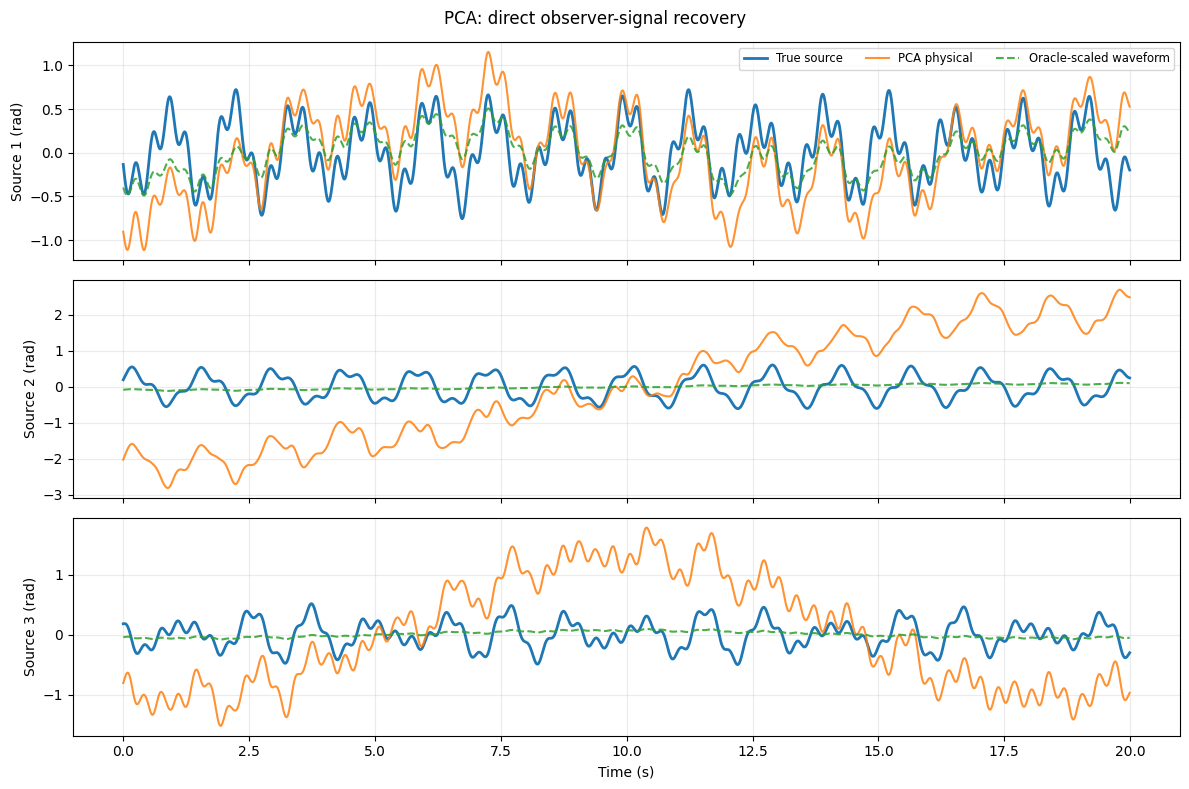

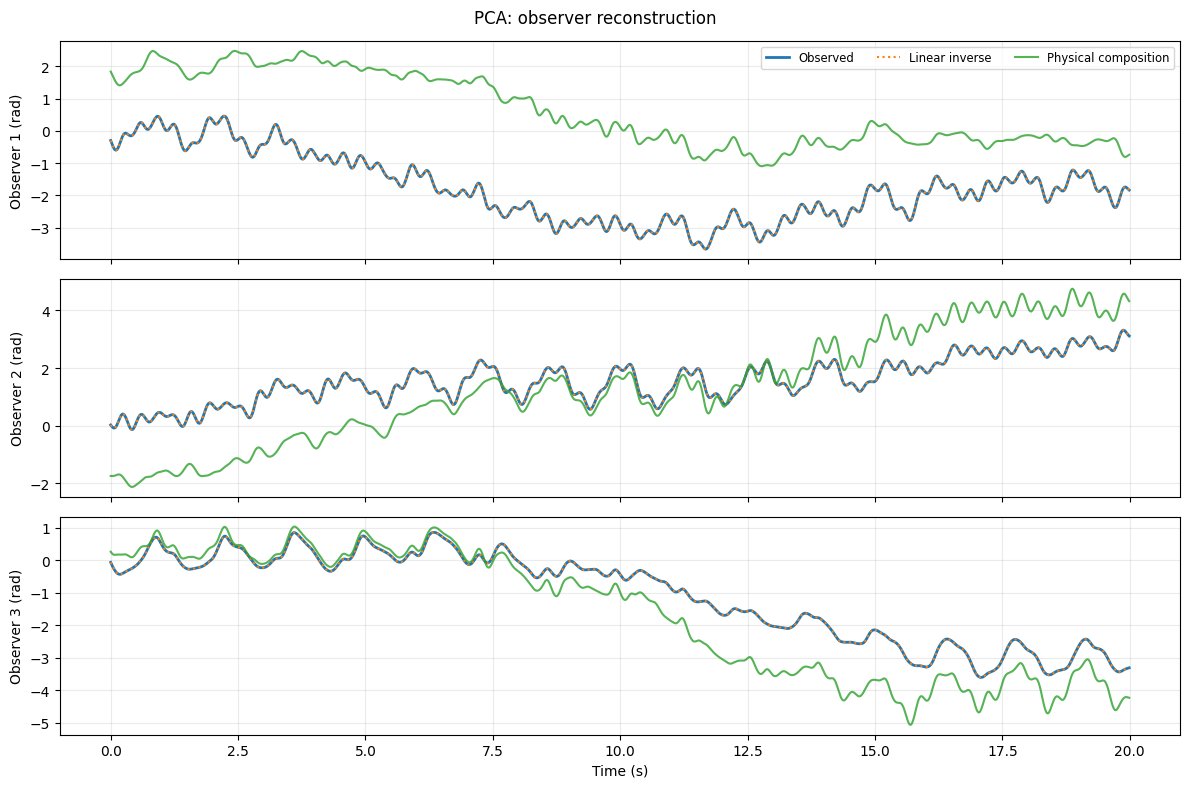

ICA (JADE)
Converged/iterations: True 4
Warnings: ()
Raw demixing matrix:
[[ 0.3491  0.0783  0.633 ]
 [ 0.963  -0.1289 -0.5575]
 [ 0.2112  1.8358  0.6198]]
Unit-axis demixing matrix:
[[ 0.4801  0.1077  0.8706]
 [ 0.8597 -0.1151 -0.4977]
 [ 0.1084  0.9419  0.318 ]]
Oracle scales: [0.4246 0.0388 0.0594]


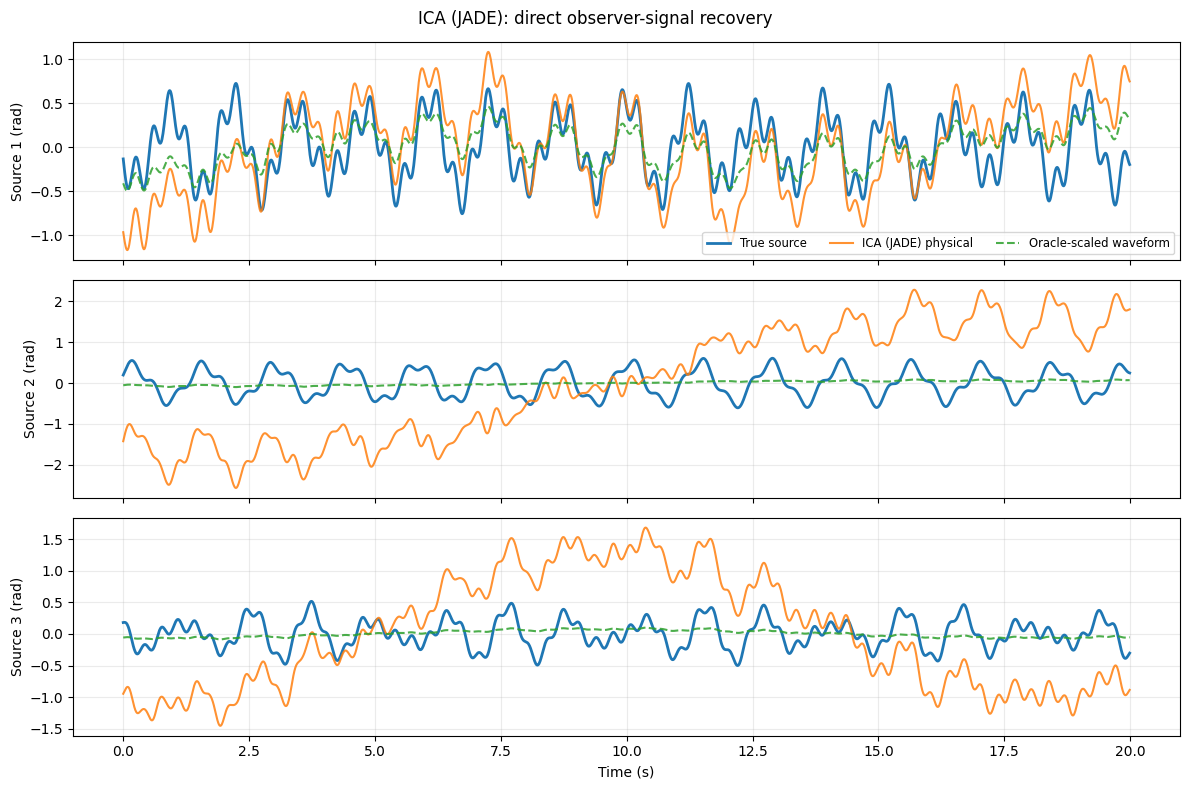

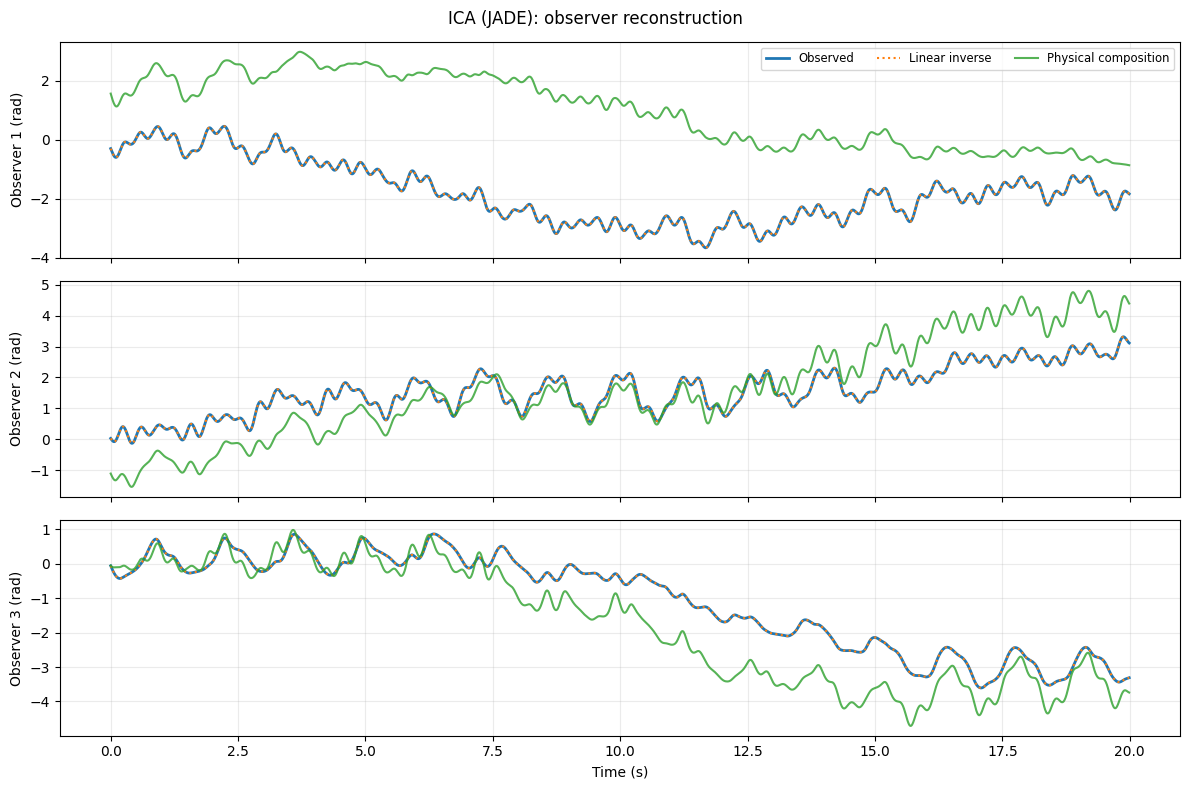

FastICA
Converged/iterations: True 13
Warnings: ()
Raw demixing matrix:
[[ 0.3576  0.0944  0.6349]
 [ 0.1986  1.8362  0.6194]
 [ 0.9626 -0.1117 -0.5559]]
Unit-axis demixing matrix:
[[ 0.4867  0.1285  0.8641]
 [ 0.1019  0.9426  0.318 ]
 [ 0.8616 -0.1    -0.4976]]
Oracle scales: [0.4231 0.0388 0.0589]


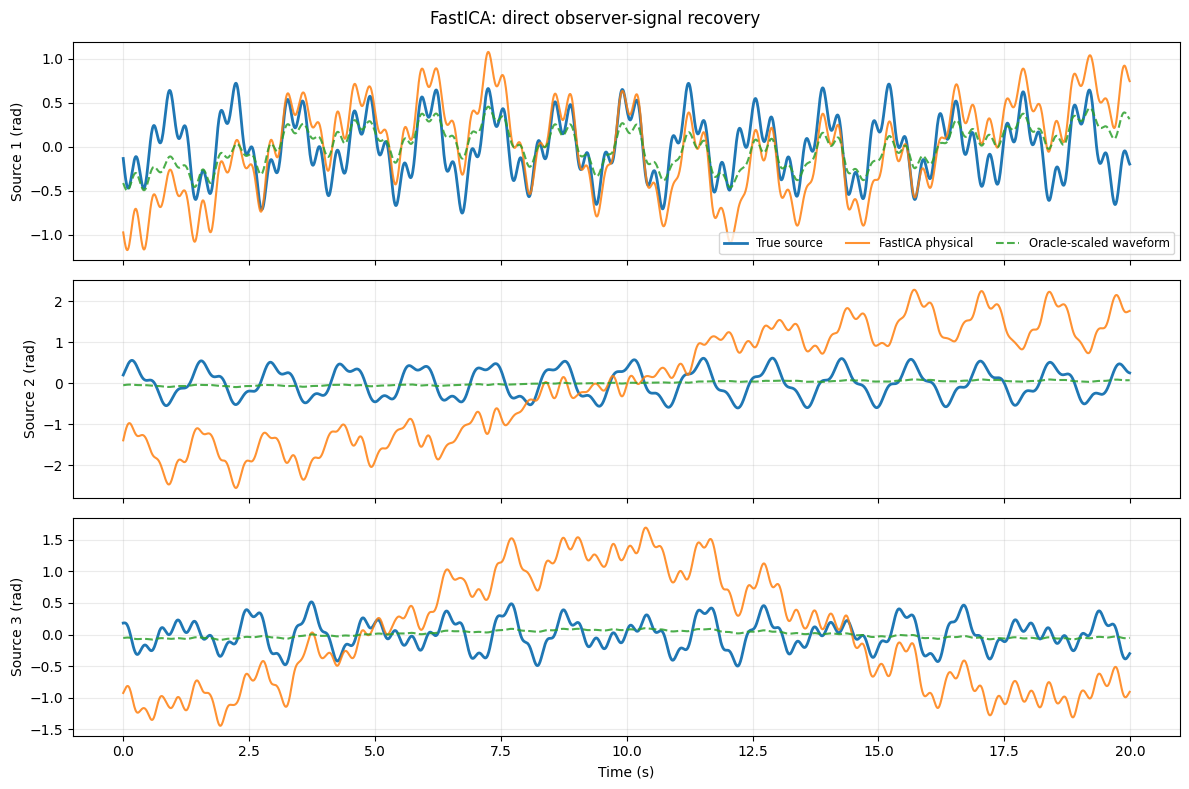

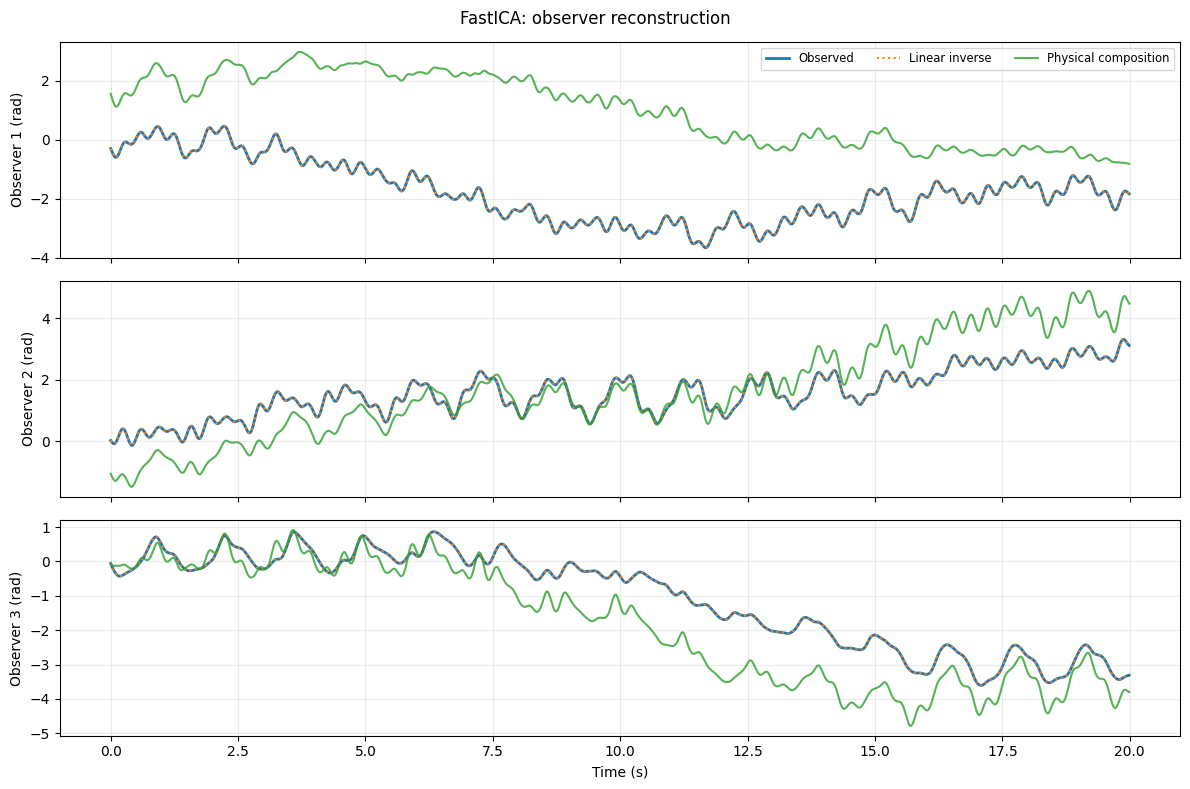

SOBI
Converged/iterations: True 3
Warnings: ()
Raw demixing matrix:
[[-0.2966  0.1855  0.8562]
 [ 0.9034 -0.471  -0.1979]
 [ 0.4355  1.7711  0.5688]]
Unit-axis demixing matrix:
[[-0.3207  0.2006  0.9257]
 [ 0.8705 -0.4538 -0.1907]
 [ 0.228   0.927   0.2977]]
Oracle scales: [0.4225 0.0348 0.0468]


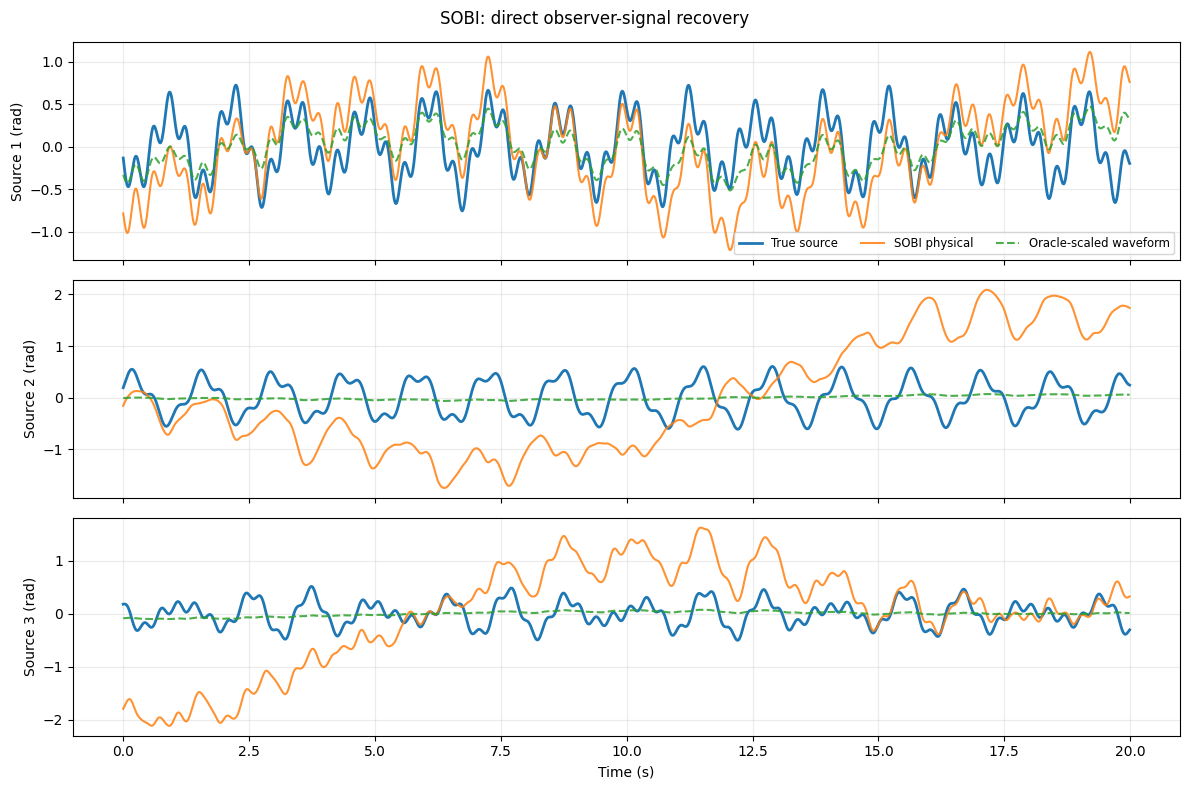

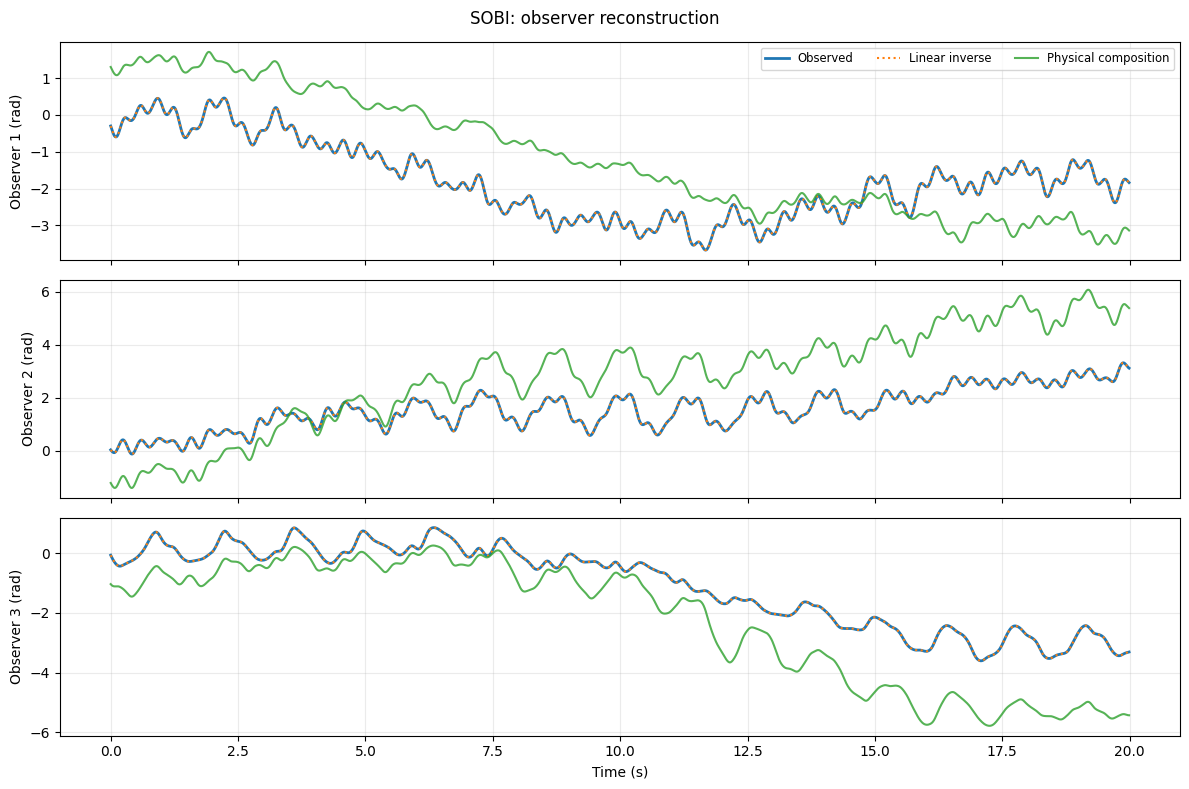

In [13]:
single_bss_results = []
if RUN_SINGLE_BSS_BASELINES:
    single_bss_results = run_and_export_bss_case(
        scenario, 'single_case', (scenario.case_id,), include_plots=True,
    )
    single_comparison_cases, single_comparison_sources, _, single_comparison_root = export_bss_suite_summaries(
        'single_case', [validation], single_bss_results,
    )
    display(single_comparison_cases[[
        'method', 'mean_abs_source_correlation', 'mean_source_rmse',
        'mean_source_rmse_oracle_scaled', 'mean_axis_error_deg',
        'quaternion_reconstruction_mean_error_deg',
        'linear_observation_reconstruction_rmse',
    ]])
    for method_result in single_bss_results:
        print(method_result.fit_result.method_label)
        print('Converged/iterations:', method_result.fit_result.converged, method_result.fit_result.iterations)
        print('Warnings:', method_result.fit_result.warnings)
        print('Raw demixing matrix:')
        print(method_result.fit_result.demixing_matrix)
        print('Unit-axis demixing matrix:')
        print(method_result.fit_result.normalized_demixing_matrix)
        print('Oracle scales:', method_result.oracle_scales)
        display_one_figure(plot_bss_source_comparison(method_result))
        display_one_figure(plot_bss_observer_reconstruction(method_result))

## 12. Standard 20-case BSS comparison

BSS standard case 1/20: harmonic_01
BSS standard case 2/20: harmonic_02
BSS standard case 3/20: harmonic_03
BSS standard case 4/20: harmonic_04
BSS standard case 5/20: harmonic_05
BSS standard case 6/20: filtered_noise_01
BSS standard case 7/20: filtered_noise_02
BSS standard case 8/20: filtered_noise_03
BSS standard case 9/20: filtered_noise_04
BSS standard case 10/20: filtered_noise_05
BSS standard case 11/20: chirp_modulated_01
BSS standard case 12/20: chirp_modulated_02
BSS standard case 13/20: chirp_modulated_03
BSS standard case 14/20: chirp_modulated_04
BSS standard case 15/20: chirp_modulated_05
BSS standard case 16/20: piecewise_transient_01
BSS standard case 17/20: piecewise_transient_02
BSS standard case 18/20: piecewise_transient_03
BSS standard case 19/20: piecewise_transient_04
BSS standard case 20/20: piecewise_transient_05


,method,family,mean_abs_source_correlation,mean_source_relative_rmse,mean_source_relative_rmse_oracle_scaled,mean_axis_error_deg,quaternion_reconstruction_mean_error_deg,linear_observation_reconstruction_rmse
0,FastICA,chirp_modulated,0.601607,1.326534,0.708946,23.479545,5.421874e+01,3.820152e-16
1,FastICA,filtered_noise,0.749133,0.804742,0.616239,34.727218,1.081462e+01,5.985764e-17
2,FastICA,harmonic,0.668327,0.992446,0.687834,23.794323,3.479794e+01,4.529469e-16
3,FastICA,piecewise_transient,0.648443,0.805323,0.730871,47.526239,2.200350e+01,1.715670e-16
4,ICA (JADE),chirp_modulated,0.602892,1.328657,0.714192,26.696042,5.146026e+01,3.932518e-16
5,ICA (JADE),filtered_noise,0.746480,0.800822,0.619537,32.454893,9.781741e+00,9.806230e-17
6,ICA (JADE),harmonic,0.672393,0.982740,0.686924,23.844397,3.428546e+01,5.146870e-16
7,ICA (JADE),piecewise_transient,0.630586,0.825646,0.739740,47.457087,2.178666e+01,1.496455e-16
8,PCA,chirp_modulated,0.596545,1.491384,0.722291,23.591414,5.542153e+01,2.268655e-16
9,PCA,filtered_noise,0.802644,0.662503,0.500390,21.035427,8.628602e+00,7.166814e-17


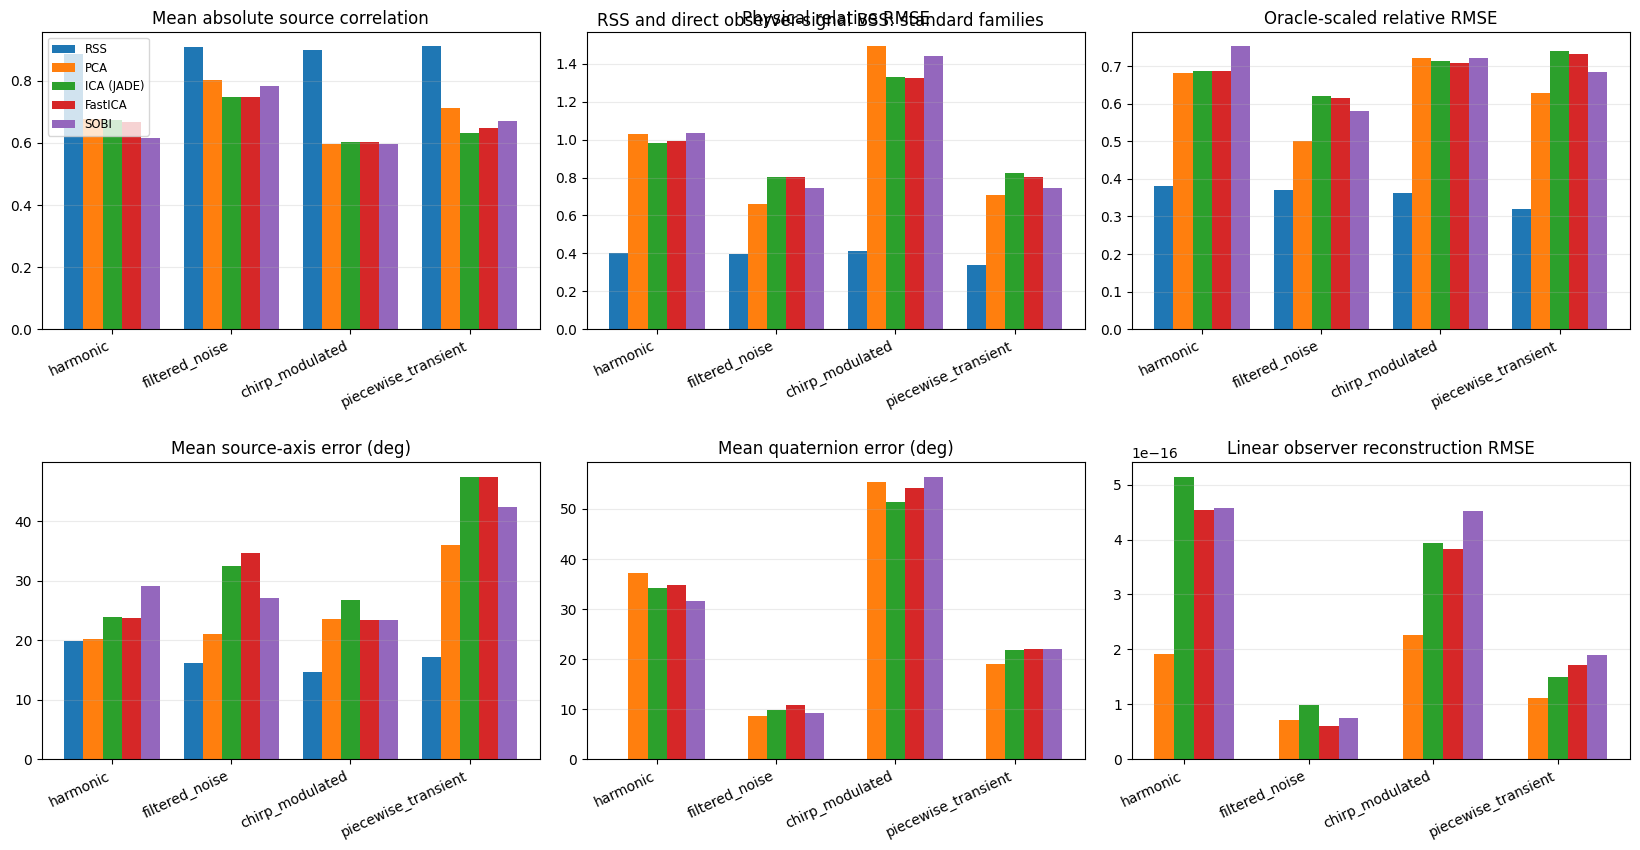

In [14]:
standard_bss_results = []
if RUN_STANDARD_BSS_SUITE:
    bss_standard_specs = create_standard_case_specs(batch_study_config)
    if QUICK_MODE:
        bss_standard_specs = bss_standard_specs[:2]
    rss_standard_scenarios = {item.scenario.case_id: item.scenario for item in standard_results}
    for index, spec in enumerate(bss_standard_specs, start=1):
        case = rss_standard_scenarios.get(spec.case_id)
        if case is None:
            case = generate_family_scenario(spec, batch_sim_config, batch_study_config)
        validate_zero_mean_sources(case)
        standard_bss_results.extend(run_and_export_bss_case(
            case, 'standard_families', (spec.family, spec.case_id), include_plots=True,
        ))
        print(f'BSS standard case {index}/{len(bss_standard_specs)}: {spec.case_id}')
    standard_comparison_cases, standard_comparison_sources, standard_method_family_means, standard_comparison_root = export_bss_suite_summaries(
        'standard_families', standard_results, standard_bss_results,
    )
    display(standard_method_family_means)
    standard_comparison_figure = plot_method_family_bars(
        standard_comparison_cases, BSS_CASE_METRIC_LABELS,
    )
    standard_comparison_figure.suptitle('RSS and direct observer-signal BSS: standard families')
    standard_comparison_figure.savefig(standard_comparison_root / 'method_family_comparison.png', dpi=150, bbox_inches='tight')
    display_one_figure(standard_comparison_figure)

## 13. Large-rotation BSS stress comparison

BSS stress case 1/8: harmonic_stress_01
BSS stress case 2/8: harmonic_stress_02
BSS stress case 3/8: harmonic_stress_03
BSS stress case 4/8: harmonic_stress_04
BSS stress case 5/8: harmonic_stress_05
BSS stress case 6/8: harmonic_stress_06
BSS stress case 7/8: harmonic_stress_07
BSS stress case 8/8: harmonic_stress_08


,method,case_id,stress_peak_angle_rad,mean_abs_source_correlation,mean_source_relative_rmse,mean_source_relative_rmse_oracle_scaled,quaternion_reconstruction_mean_error_deg
0,RSS,harmonic_stress_01,0.55,1.000000,4.522421e-14,4.520755e-14,1.034658e-14
1,RSS,harmonic_stress_02,0.85,0.999894,1.372067e-02,1.371808e-02,1.381156e-14
2,RSS,harmonic_stress_03,1.15,1.000000,3.737269e-14,3.735029e-14,1.329344e-14
3,RSS,harmonic_stress_04,1.45,0.872498,5.047584e-01,4.795427e-01,2.526465e-14
4,RSS,harmonic_stress_05,1.75,0.662409,9.080166e-01,7.431643e-01,2.504626e-14
5,RSS,harmonic_stress_06,2.05,0.440329,1.106045e+00,8.841273e-01,2.312251e-14
6,RSS,harmonic_stress_07,2.35,0.349750,1.197938e+00,9.295280e-01,2.856971e-14
7,RSS,harmonic_stress_08,2.65,0.172559,1.339324e+00,9.783043e-01,3.221116e-14
8,PCA,harmonic_stress_01,0.55,0.768791,7.677840e-01,6.322419e-01,1.711322e+01
9,ICA (JADE),harmonic_stress_01,0.55,0.628732,9.216641e-01,7.729553e-01,1.628911e+01


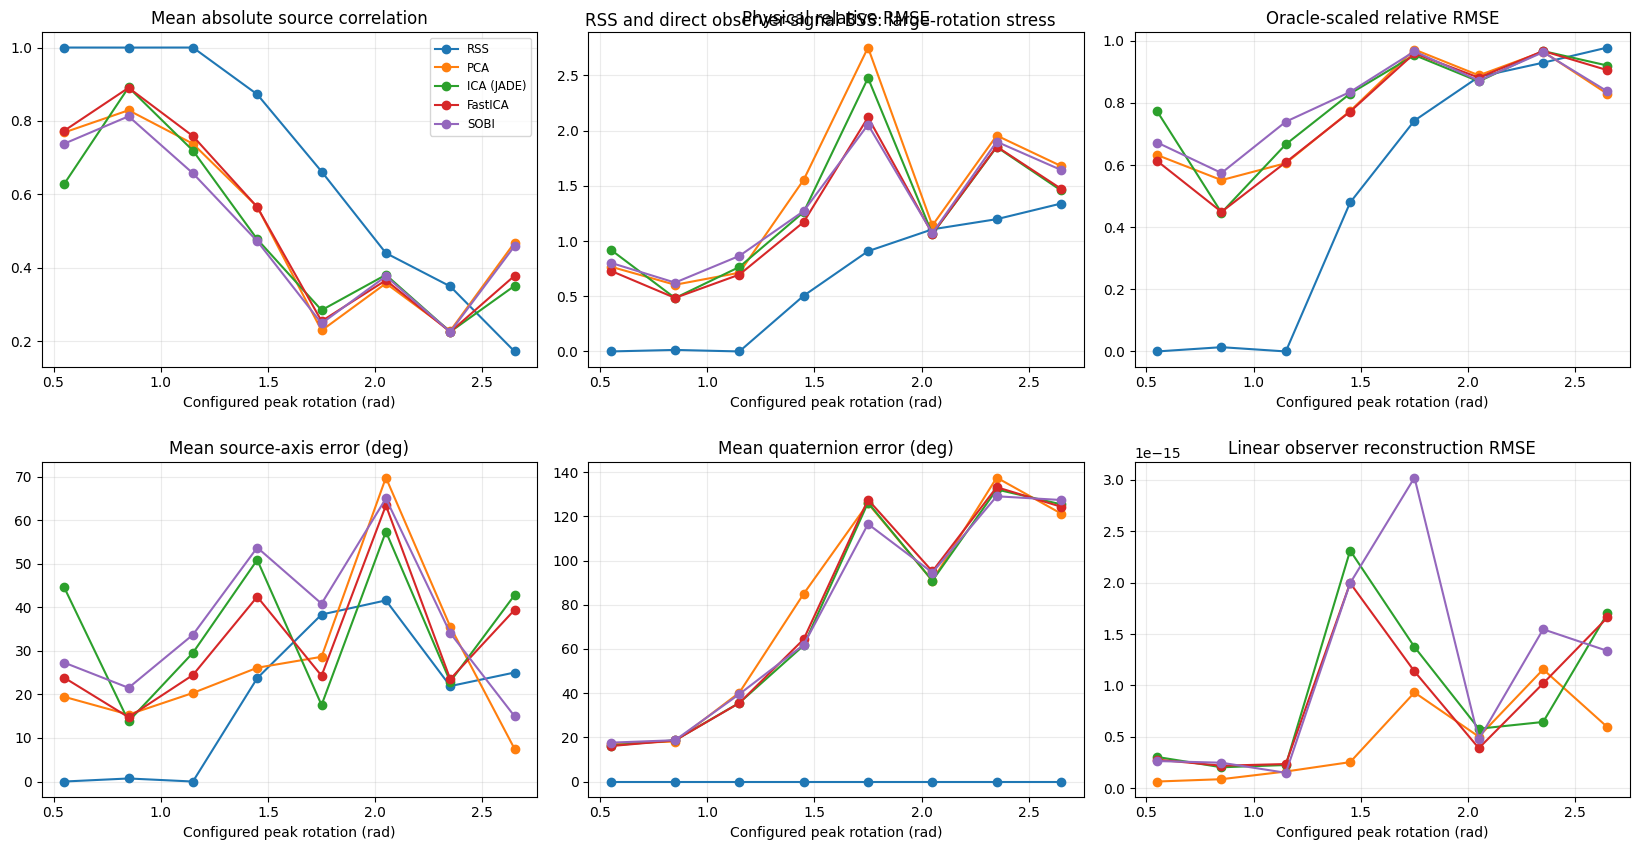

In [15]:
stress_bss_results = []
if RUN_STRESS_BSS_SUITE:
    bss_stress_specs = create_stress_case_specs(batch_study_config)
    if QUICK_MODE:
        bss_stress_specs = bss_stress_specs[:2]
    rss_stress_scenarios = {item.scenario.case_id: item.scenario for item in stress_results}
    for index, spec in enumerate(bss_stress_specs, start=1):
        case = rss_stress_scenarios.get(spec.case_id)
        if case is None:
            case = generate_family_scenario(spec, batch_sim_config, batch_study_config)
        validate_zero_mean_sources(case)
        stress_bss_results.extend(run_and_export_bss_case(
            case, 'large_rotation_stress', (spec.case_id,), include_plots=True,
        ))
        print(f'BSS stress case {index}/{len(bss_stress_specs)}: {spec.case_id}')
    stress_comparison_cases, stress_comparison_sources, _, stress_comparison_root = export_bss_suite_summaries(
        'large_rotation_stress', stress_results, stress_bss_results,
    )
    display(stress_comparison_cases[[
        'method', 'case_id', 'stress_peak_angle_rad',
        'mean_abs_source_correlation', 'mean_source_relative_rmse',
        'mean_source_relative_rmse_oracle_scaled',
        'quaternion_reconstruction_mean_error_deg',
    ]])
    stress_comparison_figure = plot_method_stress_curves(
        stress_comparison_cases, BSS_CASE_METRIC_LABELS,
    )
    stress_comparison_figure.suptitle('RSS and direct observer-signal BSS: large-rotation stress')
    stress_comparison_figure.savefig(stress_comparison_root / 'method_stress_comparison.png', dpi=150, bbox_inches='tight')
    display_one_figure(stress_comparison_figure)

## 14. Formal 200-case BSS experiment

BSS formal case 1/200: formal_harmonic_01
BSS formal case 2/200: formal_harmonic_02
BSS formal case 3/200: formal_harmonic_03
BSS formal case 4/200: formal_harmonic_04
BSS formal case 5/200: formal_harmonic_05
BSS formal case 6/200: formal_harmonic_06
BSS formal case 7/200: formal_harmonic_07
BSS formal case 8/200: formal_harmonic_08
BSS formal case 9/200: formal_harmonic_09
BSS formal case 10/200: formal_harmonic_10
BSS formal case 11/200: formal_harmonic_11
BSS formal case 12/200: formal_harmonic_12
BSS formal case 13/200: formal_harmonic_13
BSS formal case 14/200: formal_harmonic_14
BSS formal case 15/200: formal_harmonic_15
BSS formal case 16/200: formal_harmonic_16
BSS formal case 17/200: formal_harmonic_17
BSS formal case 18/200: formal_harmonic_18
BSS formal case 19/200: formal_harmonic_19
BSS formal case 20/200: formal_harmonic_20
BSS formal case 21/200: formal_harmonic_21
BSS formal case 22/200: formal_harmonic_22
BSS formal case 23/200: formal_harmonic_23
BSS formal case 24/2

,method,family,mean_abs_source_correlation,mean_source_relative_rmse,mean_source_relative_rmse_oracle_scaled,mean_axis_error_deg,quaternion_reconstruction_mean_error_deg,linear_observation_reconstruction_rmse
0,FastICA,chirp_modulated,0.559335,1.373285,0.771816,31.354434,5.124889e+01,6.912237e-16
1,FastICA,filtered_noise,0.717932,0.830824,0.647006,33.065024,1.310362e+01,1.321001e-16
2,FastICA,harmonic,0.648634,1.027076,0.688904,28.757825,3.956267e+01,4.439318e-16
3,FastICA,piecewise_transient,0.751398,0.696529,0.610332,35.077945,1.964048e+01,2.446529e-16
4,ICA (JADE),chirp_modulated,0.574718,1.398099,0.756426,29.288810,5.172824e+01,6.557777e-16
5,ICA (JADE),filtered_noise,0.718773,0.821793,0.644932,32.769641,1.274931e+01,1.414134e-16
6,ICA (JADE),harmonic,0.654798,1.015773,0.680627,28.082540,3.984987e+01,4.433323e-16
7,ICA (JADE),piecewise_transient,0.748340,0.705196,0.613360,34.918605,1.979972e+01,2.441790e-16
8,PCA,chirp_modulated,0.607555,1.686750,0.724016,17.281232,6.237205e+01,3.299161e-16
9,PCA,filtered_noise,0.777655,0.741344,0.546669,24.080042,1.300231e+01,7.895978e-17


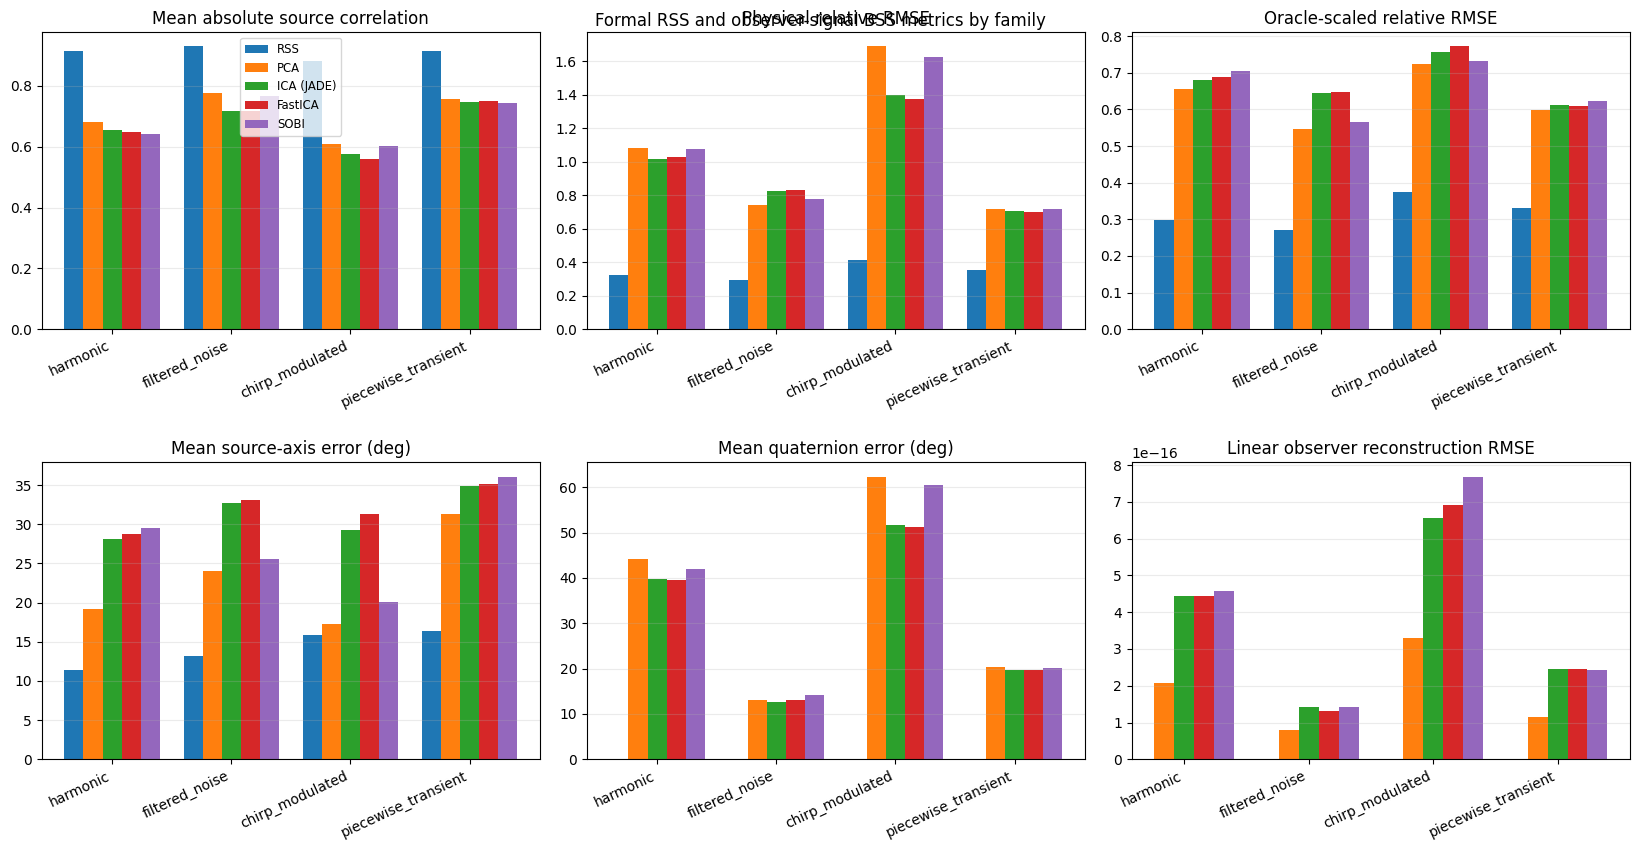

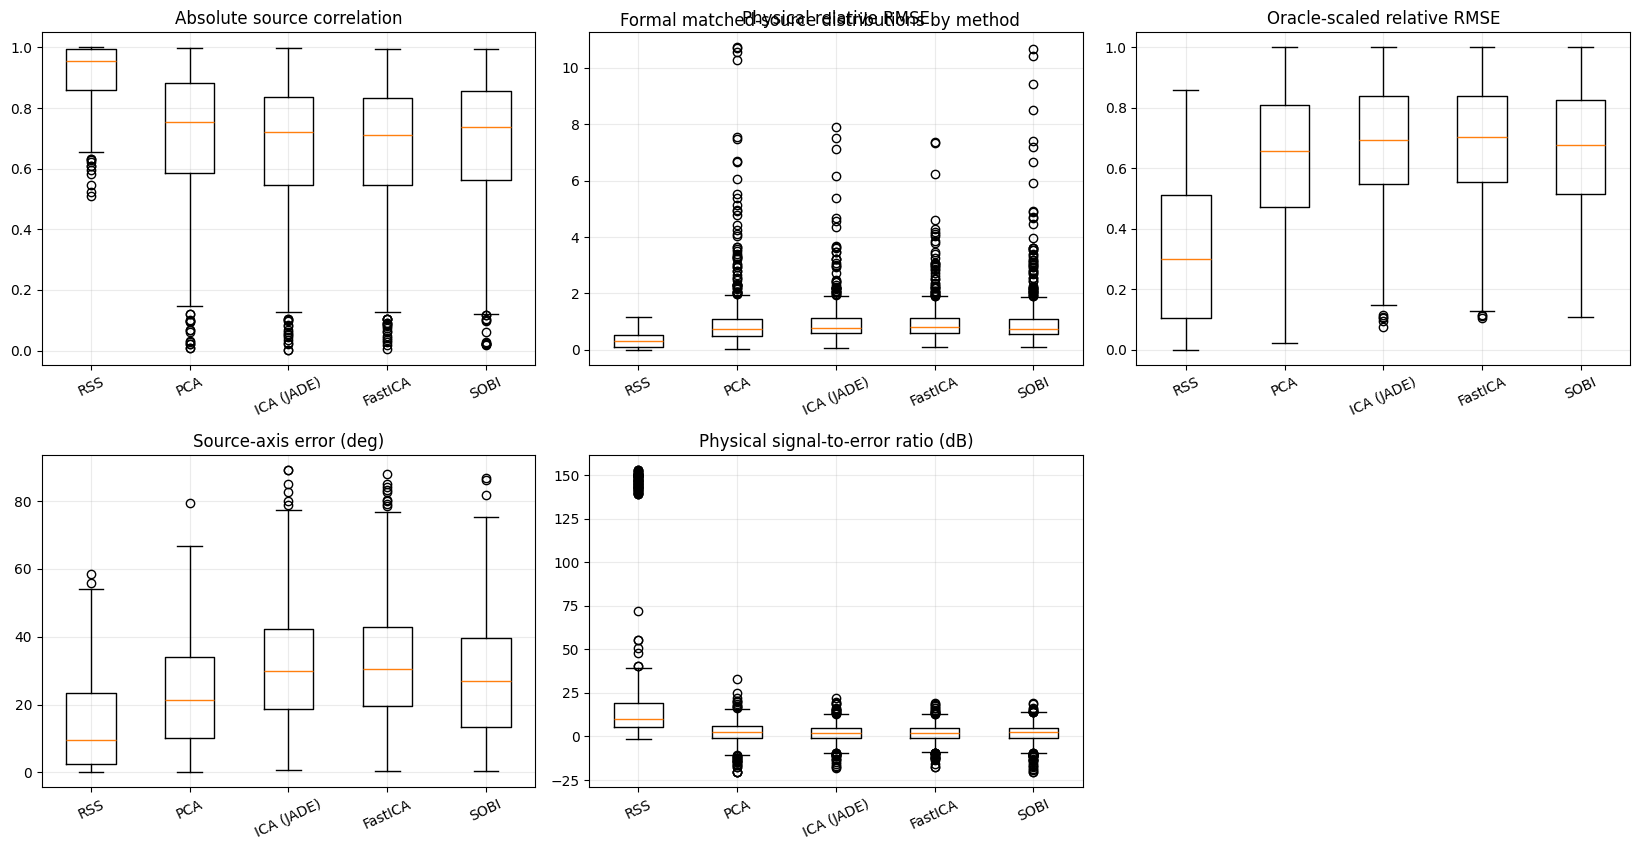

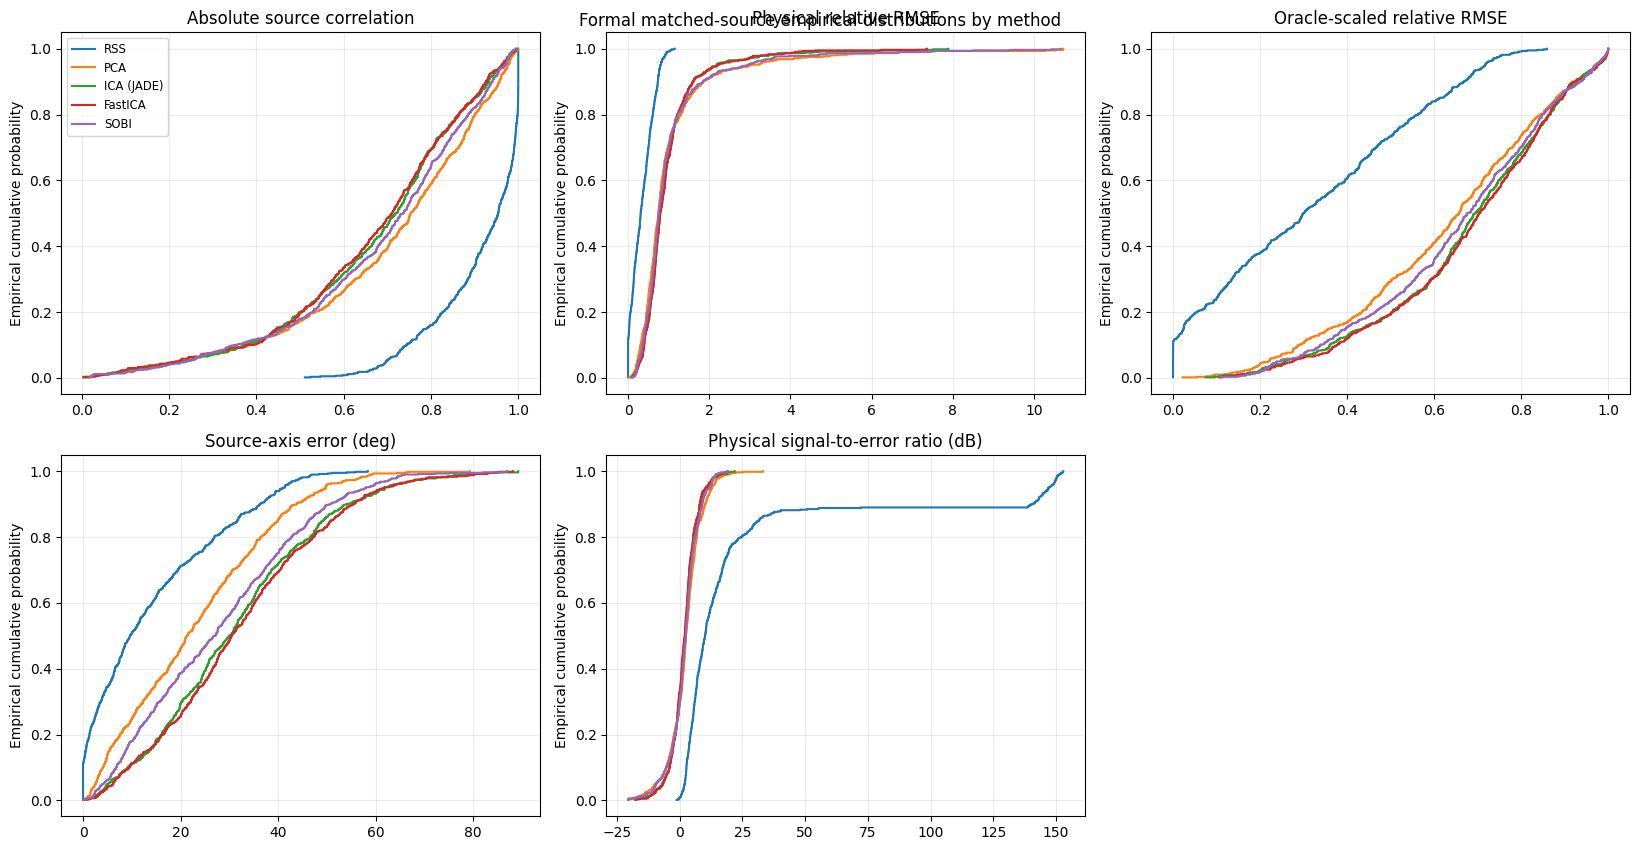

In [16]:
formal_bss_results = []
if RUN_FORMAL_BSS_SUITE:
    bss_formal_specs = create_standard_case_specs(
        formal_study_config, base_seed=formal_base_seed, case_id_prefix='formal_',
    )
    if QUICK_MODE:
        bss_formal_specs = [
            next(spec for spec in bss_formal_specs if spec.family == family)
            for family in formal_study_config.standard_families
        ]
    rss_formal_scenarios = {item.scenario.case_id: item.scenario for item in formal_results}
    for index, spec in enumerate(bss_formal_specs, start=1):
        case = rss_formal_scenarios.get(spec.case_id)
        if case is None:
            case = generate_family_scenario(spec, batch_sim_config, formal_study_config)
        validate_zero_mean_sources(case)
        if case.source_roles != ('dense', 'dense', 'dense') or case.active_source_indices != (0, 1, 2):
            raise RuntimeError(f'Formal BSS case {spec.case_id} does not contain three active rotation sources.')
        formal_bss_results.extend(run_and_export_bss_case(
            case, 'formal_experiments', (spec.family, spec.case_id), include_plots=False,
        ))
        print(f'BSS formal case {index}/{len(bss_formal_specs)}: {spec.case_id}')
    formal_comparison_cases, formal_comparison_sources, formal_method_family_means, formal_comparison_root = export_bss_suite_summaries(
        'formal_experiments', formal_results, formal_bss_results,
    )
    display(formal_method_family_means)
    formal_method_bars = plot_method_family_bars(
        formal_comparison_cases, BSS_CASE_METRIC_LABELS,
    )
    formal_method_bars.suptitle('Formal RSS and observer-signal BSS metrics by family')
    formal_method_bars.savefig(formal_comparison_root / 'method_family_comparison.png', dpi=150, bbox_inches='tight')
    display_one_figure(formal_method_bars)
    formal_method_boxplots = plot_method_distribution_grid(
        formal_comparison_sources, BSS_SOURCE_METRIC_LABELS, kind='box',
    )
    formal_method_boxplots.suptitle('Formal matched-source distributions by method')
    formal_method_boxplots.savefig(formal_comparison_root / 'method_source_metric_boxplots.png', dpi=150, bbox_inches='tight')
    display_one_figure(formal_method_boxplots)
    formal_method_ecdfs = plot_method_distribution_grid(
        formal_comparison_sources, BSS_SOURCE_METRIC_LABELS, kind='ecdf',
    )
    formal_method_ecdfs.suptitle('Formal matched-source empirical distributions by method')
    formal_method_ecdfs.savefig(formal_comparison_root / 'method_source_metric_ecdfs.png', dpi=150, bbox_inches='tight')
    display_one_figure(formal_method_ecdfs)

## 15. BSS artifact summary

In [17]:
print('BSS validation artifact root:', BSS_ARTIFACT_ROOT)
print('Single-case BSS fits completed:', len(single_bss_results))
print('Standard BSS fits completed:', len(standard_bss_results))
print('Stress BSS fits completed:', len(stress_bss_results))
print('Formal BSS fits completed:', len(formal_bss_results))
print('Expected full-study BSS fits: 4 single + 80 standard + 32 stress + 800 formal = 916')

BSS validation artifact root: notebooks/artifacts/rss_validation/bss_baselines
Single-case BSS fits completed: 4
Standard BSS fits completed: 80
Stress BSS fits completed: 32
Formal BSS fits completed: 800
Expected full-study BSS fits: 4 single + 80 standard + 32 stress + 800 formal = 916


## 16. Inter-source correlation sensitivity configuration

RSS minimizes the zero-lag cross-correlation between separated sources, so statistical
independence of the sources is one of its modelling assumptions rather than an incidental
property of the simulator. Every suite above is generated with that assumption satisfied:
`_decorrelate_source_angles` whitens each scenario to below `source_cross_correlation_limit`.

This suite deliberately violates it in a controlled way. Each scenario's sources are
symmetrically whitened and then recolored by the symmetric square root of an equicorrelated
target `R(rho) = (1 - rho) I + rho 11^T`, so every source pair sits at exactly `rho`. Peak
amplitudes and temporal means are preserved, and because correlation is invariant to positive
per-row scaling and to constant shifts, the later zero-mean centering leaves `rho` untouched.
The usual cross-correlation gate is bypassed for this suite only, and the realized correlation
is verified against the requested target instead.

The design is paired. Every correlation level inside a `(family, replicate)` block reuses the
same seed, so the waveforms, source axes, observer axes, and mixing matrix are identical across
levels and the correlation is the only factor that varies. Bootstrap intervals therefore
resample whole blocks rather than individual cases.

Two thresholds are reported per method. The absolute criterion is the largest `rho` keeping the
error below 1%; because every method's error floor at `rho = 0` already exceeds that, it is
expected to report `not attained at rho=0`, which is recorded honestly rather than hidden. The
headline criterion is the largest `rho` at which a method's error stays within 1% of its own
`rho -> 0` baseline, which stays well defined regardless of where that floor sits.

In [18]:
CORRELATION_SUITE_NAME = 'correlation_sensitivity'
RUN_CORRELATION_SENSITIVITY_SWEEP = True

correlation_study_config = CorrelationStudyConfig(
    # Log-spaced: the degradation onset sits orders of magnitude below the largest level,
    # so a linear grid over the same range would resolve almost nothing.
    target_correlations=(0.0, 0.6) if QUICK_MODE else (
        0.0, 1e-4, 3e-4, 1e-3, 3e-3, 1e-2, 3e-2, 1e-1, 3e-1, 0.9,
    ),
    families=('harmonic',) if QUICK_MODE else (
        'harmonic', 'filtered_noise', 'chirp_modulated', 'piecewise_transient',
    ),
    replicates=1 if QUICK_MODE else 10,
    dt=0.01,
    base_seed=31000,
)
correlation_sweep_config = CorrelationSweepConfig(
    study=correlation_study_config,
    include_rss=True,
    primary_metric='mean_axis_error_deg',
    absolute_thresholds=(0.01,),
    relative_degradations=(0.01,),
    bootstrap_resamples=200 if QUICK_MODE else 2000,
    bootstrap_seed=0,
    retain_case_results=True,
)

# The axis error leads because it is stable under the optimizer's run-to-run branch
# selection and does not rely on the correlation-based source matching, which becomes
# ambiguous once the true sources are themselves correlated.
CORRELATION_METRIC_LABELS = {
    'mean_axis_error_deg': 'Mean source-axis error (deg)',
    'mean_source_relative_rmse_oracle_scaled': 'Oracle-scaled relative RMSE',
    'mean_abs_source_correlation': 'Mean absolute source correlation',
}
CORRELATION_ARTIFACT_ROOT = BSS_ARTIFACT_ROOT / 'comparisons' / CORRELATION_SUITE_NAME / 'summary'

# The correlation suite reuses batch_rss_config unchanged so its RSS operating point is
# identical to sections 6-8 and the comparison stays like-for-like. Sequence length comes
# from the batch study config, so quick mode only has to shrink that.

def export_correlation_case(outcome):
    """Persist one correlation case and report progress."""
    validate_zero_mean_sources(outcome.scenario)
    for method_result in outcome.bss_results:
        export_bss_case_artifacts(
            method_result,
            BSS_ARTIFACT_ROOT / method_result.fit_result.method_key / CORRELATION_SUITE_NAME / 'cases' / outcome.spec.case_id,
            include_plots=False,
        )
    if outcome.rss_result is not None:
        export_validation_case_artifacts(
            outcome.rss_result,
            BATCH_ARTIFACT_ROOT / CORRELATION_SUITE_NAME / 'cases' / outcome.spec.case_id,
            include_plots=False,
        )
    print(f'Correlation case {outcome.spec.case_id}: rho={outcome.spec.target_source_correlation:g}')

print('Correlation levels:', correlation_study_config.target_correlations)
print('Correlation families:', correlation_study_config.families)
print('Correlation replicates per family:', correlation_study_config.replicates)
print('Correlation artifact root:', CORRELATION_ARTIFACT_ROOT)

Correlation levels: (0.0, 0.0001, 0.0003, 0.001, 0.003, 0.01, 0.03, 0.1, 0.3, 0.9)
Correlation families: ('harmonic', 'filtered_noise', 'chirp_modulated', 'piecewise_transient')
Correlation replicates per family: 10
Correlation artifact root: notebooks/artifacts/rss_validation/bss_baselines/comparisons/correlation_sensitivity/summary


## 17. Correlation sweep execution and degradation curves

Each case is generated at an exact target correlation, then RSS and all four observer-signal
baselines are fitted to the identical observations. Curves show the block mean per method with
bootstrap bands; the correlation axis is logarithmic and the zero level is drawn at the left.

Correlation case corr_harmonic_01_rhop0: rho=0
Correlation case corr_harmonic_01_rhop0_0001: rho=0.0001
Correlation case corr_harmonic_01_rhop0_0003: rho=0.0003
Correlation case corr_harmonic_01_rhop0_001: rho=0.001
Correlation case corr_harmonic_01_rhop0_003: rho=0.003
Correlation case corr_harmonic_01_rhop0_01: rho=0.01
Correlation case corr_harmonic_01_rhop0_03: rho=0.03
Correlation case corr_harmonic_01_rhop0_1: rho=0.1
Correlation case corr_harmonic_01_rhop0_3: rho=0.3
Correlation case corr_harmonic_01_rhop0_9: rho=0.9
Correlation case corr_harmonic_02_rhop0: rho=0
Correlation case corr_harmonic_02_rhop0_0001: rho=0.0001
Correlation case corr_harmonic_02_rhop0_0003: rho=0.0003
Correlation case corr_harmonic_02_rhop0_001: rho=0.001
Correlation case corr_harmonic_02_rhop0_003: rho=0.003
Correlation case corr_harmonic_02_rhop0_01: rho=0.01
Correlation case corr_harmonic_02_rhop0_03: rho=0.03
Correlation case corr_harmonic_02_rhop0_1: rho=0.1
Correlation case corr_harmonic_02_rhop0_3:

,method,target_source_correlation,count,mean,median,ci_lower,ci_upper
0,RSS,0.0000,40,12.402876,8.263917,8.650463,16.437343
5,RSS,0.0001,40,12.423248,8.292385,8.746048,16.534168
10,RSS,0.0003,40,13.357010,9.351002,9.474405,17.335216
15,RSS,0.0010,40,14.000870,9.660197,10.072258,18.294280
20,RSS,0.0030,40,13.029683,9.834807,9.336798,17.014755
25,RSS,0.0100,40,14.013867,12.758094,10.632296,17.491963
30,RSS,0.0300,40,16.431094,15.734901,13.096773,20.012330
35,RSS,0.1000,40,24.848487,25.072973,21.170977,28.709333
40,RSS,0.3000,40,33.779697,34.837177,31.453144,36.028481
45,RSS,0.9000,40,44.008774,42.743676,41.920415,46.140262


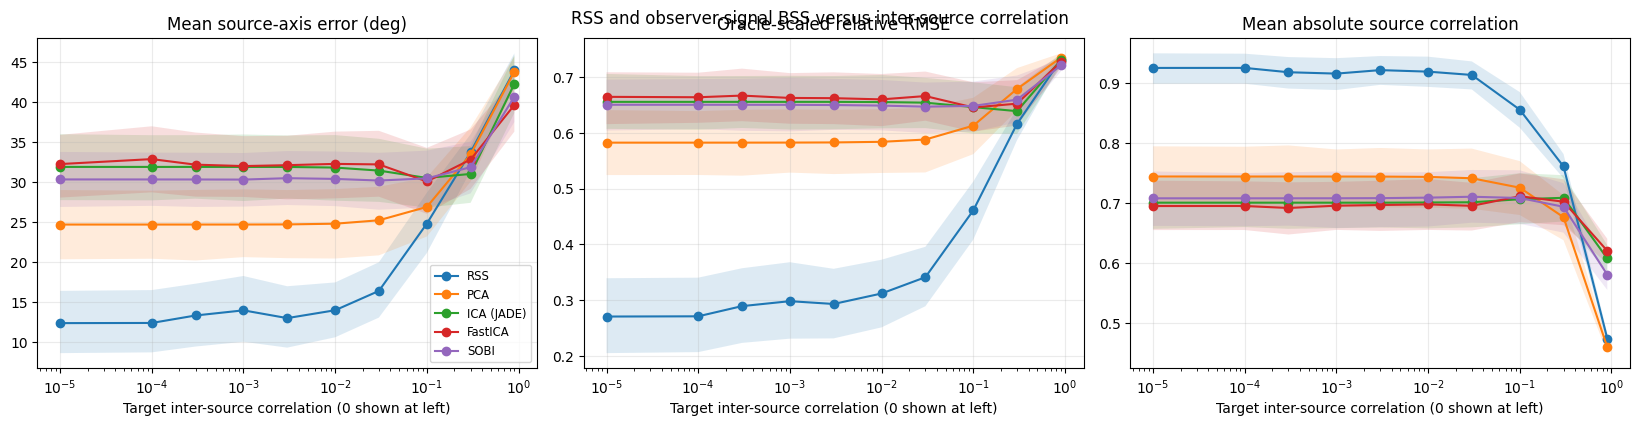

In [19]:
correlation_sweep = None
if RUN_CORRELATION_SENSITIVITY_SWEEP:
    correlation_batch_study = replace(batch_study_config, batch_sequence_lengths=(96,)) if QUICK_MODE else batch_study_config
    correlation_sweep = run_correlation_sensitivity_sweep(
        batch_rss_config,
        bss_config,
        correlation_sweep_config,
        base_config=batch_sim_config,
        study_config=correlation_batch_study,
        case_callback=export_correlation_case,
    )
    CORRELATION_ARTIFACT_ROOT.mkdir(parents=True, exist_ok=True)
    correlation_sweep.case_frame.to_csv(CORRELATION_ARTIFACT_ROOT / 'per_case_metrics.csv', index=False)
    correlation_sweep.source_frame.to_csv(CORRELATION_ARTIFACT_ROOT / 'per_source_metrics.csv', index=False)
    correlation_sweep.case_summary.to_csv(CORRELATION_ARTIFACT_ROOT / 'correlation_metric_summary.csv', index=False)

    # The recorded column averages absolute pair correlations, so it is compared against
    # |target|; every pair of an equicorrelated target sits at exactly rho.
    realized_deviation = (
        correlation_sweep.case_frame['target_source_correlation'].abs()
        - correlation_sweep.case_frame['original_source_mean_abs_cross_correlation']
    ).abs().max()
    print('Correlation cases fitted:', len(correlation_sweep.case_frame))
    print('Maximum |target - realized| source correlation:', float(realized_deviation))

    correlation_primary_summary = correlation_sweep.case_summary.loc[
        correlation_sweep.case_summary['metric'] == correlation_sweep_config.primary_metric
    ]
    display(correlation_primary_summary[[
        'method', 'target_source_correlation', 'count', 'mean', 'median', 'ci_lower', 'ci_upper',
    ]])

    correlation_curves = plot_method_correlation_curves(
        correlation_sweep.case_frame,
        CORRELATION_METRIC_LABELS,
        summary=correlation_sweep.case_summary,
    )
    correlation_curves.suptitle('RSS and observer-signal BSS versus inter-source correlation')
    correlation_curves.savefig(
        CORRELATION_ARTIFACT_ROOT / 'method_correlation_curves.png', dpi=150, bbox_inches='tight',
    )
    display_one_figure(correlation_curves)

## 18. Correlation breakdown thresholds

`threshold_correlation` is the geometric mean over blocks of the first upcrossing of each
criterion, with a block-bootstrap interval; `p05_correlation` is the conservative value to
design to. `status` distinguishes a genuine crossing from a criterion that was already
violated at zero correlation, and from one never reached inside the grid.

In [20]:
if correlation_sweep is not None:
    correlation_thresholds = correlation_sweep.thresholds
    correlation_thresholds.to_csv(CORRELATION_ARTIFACT_ROOT / 'correlation_thresholds.csv', index=False)
    display(correlation_thresholds[[
        'method', 'metric', 'criterion', 'criterion_value', 'threshold_correlation',
        'ci_lower', 'ci_upper', 'p05_correlation', 'status', 'baseline_error_at_zero',
    ]])

    if not correlation_sweep.paired_tests.empty:
        correlation_sweep.paired_tests.to_csv(
            CORRELATION_ARTIFACT_ROOT / 'correlation_paired_tests.csv', index=False,
        )
        display(correlation_sweep.paired_tests[[
            'target_source_correlation', 'method', 'block_count', 'error_ratio',
            'reference_win_rate', 'p_value', 'p_value_holm',
        ]])
    print('Correlation sensitivity artifacts:', CORRELATION_ARTIFACT_ROOT)

,method,metric,criterion,criterion_value,threshold_correlation,ci_lower,ci_upper,p05_correlation,status,baseline_error_at_zero
0,RSS,mean_axis_error_deg,absolute,0.01,0.000028,1.372147e-05,0.000055,9.466570e-06,attained,1.240288e+01
1,RSS,mean_axis_error_deg,relative_degradation,0.01,0.001671,2.150848e-04,0.009358,5.635799e-08,attained,1.240288e+01
2,RSS,mean_source_relative_rmse_oracle_scaled,absolute,0.01,0.000909,4.790720e-04,0.001751,3.050377e-04,attained,2.704700e-01
3,RSS,mean_source_relative_rmse_oracle_scaled,relative_degradation,0.01,0.000025,3.099644e-07,0.001147,9.916338e-18,attained,2.704700e-01
4,RSS,mean_source_relative_rmse,absolute,0.01,0.000907,4.944301e-04,0.001811,3.043831e-04,attained,2.876309e-01
5,RSS,mean_source_relative_rmse,relative_degradation,0.01,0.000022,2.841374e-07,0.000855,9.920617e-18,attained,2.876309e-01
6,RSS,mean_abs_source_correlation,absolute,0.01,NaN,NaN,NaN,NaN,not attained at rho=0,9.258865e-01
7,RSS,mean_abs_source_correlation,relative_degradation,0.01,0.040013,1.499706e-02,0.105601,5.193439e-04,attained,9.258865e-01
8,RSS,quaternion_reconstruction_mean_error_deg,absolute,0.01,0.900000,9.000000e-01,0.900000,9.000000e-01,above grid max,1.017875e-14
9,RSS,quaternion_reconstruction_mean_error_deg,relative_degradation,0.01,0.000082,2.800428e-05,0.000245,1.184028e-06,attained,1.017875e-14


,target_source_correlation,method,block_count,error_ratio,reference_win_rate,p_value,p_value_holm
0,0.0000,PCA,35,0.399057,0.857143,1.510460e-04,2.114644e-03
1,0.0000,ICA (JADE),35,0.289635,0.828571,3.254972e-06,7.486437e-05
2,0.0000,FastICA,35,0.297165,0.857143,3.647117e-06,8.023658e-05
3,0.0000,SOBI,35,0.297979,0.914286,1.609442e-07,4.667381e-06
4,0.0001,PCA,40,0.262517,0.875000,5.371159e-06,1.074232e-04
5,0.0001,ICA (JADE),40,0.165538,0.850000,1.036697e-07,3.317429e-06
6,0.0001,FastICA,40,0.164046,0.900000,6.460687e-08,2.325847e-06
7,0.0001,SOBI,40,0.161224,0.925000,5.029506e-09,1.961507e-07
8,0.0003,PCA,40,0.303784,0.825000,3.545586e-05,6.027497e-04
9,0.0003,ICA (JADE),40,0.189454,0.875000,1.163498e-07,3.606845e-06


Correlation sensitivity artifacts: notebooks/artifacts/rss_validation/bss_baselines/comparisons/correlation_sensitivity/summary


## 19. Source-signal centering and edge-transient audit

Every scenario is audited at generation time. This final table reports the unique cases actually exercised by the enabled suites. `max_abs_temporal_mean` covers `generated_sources`, `relative_sources`, and the recovery truth `sources`; active traces must contain both positive and negative samples. The edge-RMS check applies to filtered noise, where an AR-filter initialization artifact is meaningful. It is deliberately not applied to the nonstationary chirp or `piecewise_transient` families.

In [ ]:
source_signal_audit_frame = pd.DataFrame(SOURCE_SIGNAL_AUDIT.values())
if source_signal_audit_frame.empty:
    raise RuntimeError('No source scenarios were audited. Run the enabled experiment sections first.')

formal_source_audit = source_signal_audit_frame.loc[
    source_signal_audit_frame['case_id'].str.startswith('formal_')
]
if not QUICK_MODE and (RUN_FORMAL_EXPERIMENT_SUITE or RUN_FORMAL_BSS_SUITE):
    if len(formal_source_audit) != 200:
        raise RuntimeError(
            f'Expected 200 audited formal cases, found {len(formal_source_audit)}.'
        )

source_signal_audit_summary = (
    source_signal_audit_frame.groupby('family', as_index=False)
    .agg(
        cases=('case_id', 'nunique'),
        active_signals=('active_source_count', 'sum'),
        max_abs_temporal_mean=('max_abs_temporal_mean', 'max'),
        all_cross_time_axis=('all_active_sources_cross_time_axis', 'all'),
        max_filtered_noise_edge_rms_ratio=(
            'filtered_noise_max_edge_rms_ratio', 'max'
        ),
    )
)
display(source_signal_audit_summary)
print(
    'Audited unique scenarios / active source signals:',
    len(source_signal_audit_frame),
    '/',
    int(source_signal_audit_frame['active_source_count'].sum()),
)
print(
    'Formal 200-case scenarios / active source signals:',
    len(formal_source_audit),
    '/',
    int(formal_source_audit['active_source_count'].sum()),
)
print(
    'Maximum absolute temporal mean:',
    source_signal_audit_frame['max_abs_temporal_mean'].max(),
)